# CMP629 — MountainCar: entrega final

**60 treinamentos finais validados**, além das 108 execuções históricas preservadas. Modo apresentação, sem retreino por padrão. A campanha final usa 10 seeds de treinamento por algoritmo/grade, 100 episódios de avaliação por política e hiperparâmetros congelados pela triagem. Vídeos finais carregam checkpoints reais; os vídeos de smoke permanecem identificados separadamente.

Todos os gráficos e vídeos exibidos são da campanha final. A proveniência da triagem aparece em apêndice, sem misturar amostras.

In [1]:
RUN_TRAINING = False
RUN_DEMO = False
import io, json, gzip, hashlib, urllib.request, pathlib, zipfile
import numpy as np
import pandas as pd
from IPython.display import display, Image, Video, Markdown
BRANCH = "codex/cmp629-fase-a-20261011"
BASE = f"https://raw.githubusercontent.com/antoniomoraes85/reinforcement-learning-projects/{BRANCH}/mountaincar-tabular"
OUT = pathlib.Path("cmp629_apresentacao")
OUT.mkdir(exist_ok=True)
def fetch(relative):
    with urllib.request.urlopen(f"{BASE}/{relative}", timeout=60) as response:
        return response.read()
manifest = json.loads(fetch("dados/auditoria_v2/manifesto_publicacao.json"))
def verified(relative):
    data = fetch(relative)
    assert hashlib.sha256(data).hexdigest() == manifest[relative], relative
    return data
print("Modo apresentação; fonte pública:", BRANCH)

Modo apresentação; fonte pública: codex/cmp629-fase-a-20261011


## Contexto e métodos
O carro precisa chegar à posição 0,5 usando embalo. Observação contínua: posição e velocidade. Ações 0/1/2: esquerda/neutro/direita; recompensa −1 por passo; limite padrão de 200 passos. Discretizações não uniformes 4×2 e 12×4, conforme protocolo.

| Método | Política de atualização | Modelo |
|---|---|---|
| Q-learning | off-policy (alvo greedy) | model-free |
| SARSA(λ) | on-policy (próxima ação ε-greedy) | model-free com traços acumulativos |
| Dyna-Q | off-policy | aprendizado direto + planejamento com modelo empírico |

Q-learning: $Q(s,a)\leftarrow Q(s,a)+\alpha[r+\gamma\max_b Q(s',b)-Q(s,a)]$.
SARSA: $\delta=r+\gamma Q(s',a')-Q(s,a)$; $e(s,a)\leftarrow e(s,a)+1$; $Q\leftarrow Q+\alpha\delta e$; $e\leftarrow\gamma\lambda e$. Traços zerados a cada episódio.
Dyna-Q faz um backup real e N backups de desfechos amostrados do modelo. Cada par discreto armazena contagens de múltiplos desfechos, pois a discretização agrega estados contínuos.

Em término real, bootstrap zero. Em truncamento por tempo, mantemos bootstrap: aproximação do processo subjacente sem término, embora a avaliação continue limitada a 200 passos. Isso não é uma solução tabular exata do MDP finito de 200 passos (tempo não está no estado).

### Hipóteses e limites
Desempates greedy aleatórios reprodutíveis. γ=0,99. Seleção global pela AUC média de treinamento nas duas discretizações; avaliação não usada para selecionar. Seeds de treino são a unidade independente; episódios avaliados não são replicações de treinamento. Avaliação histórica usava seeds derivadas de cada seed de treino; v2 usa o mesmo conjunto fixo para todas as políticas. Isso impede tratar as duas campanhas como réplicas idênticas.

## Campanha final: 60 políticas independentes

Dez seeds por célula; IC calculado entre políticas. As 100 avaliações de uma política não são 100 treinamentos. Retorno e duração são redundantes neste benchmark (recompensa −1 por passo), mas registrados separadamente para auditoria. Parâmetros globais não foram reajustados pelo teste final.

In [2]:
final_histories=json.loads(gzip.decompress(verified("dados/auditoria_v2/final_historicos.json.gz")))
assert len(final_histories)==60 and len({r["config_hash"] for r in final_histories})==60
final_metrics=pd.read_csv(io.BytesIO(verified("relatorios/final_v2/metricas_por_seed.csv")))
final_summary=pd.read_csv(io.BytesIO(verified("relatorios/final_v2/estatisticas_entre_seeds.csv")))
display(final_summary[final_summary.metric.isin(["evaluation_success_rate","mean_steps_all","mean_steps_success"])].round(4))
display(Markdown(verified("relatorios/final_v2/RESULTADOS.md").decode("utf-8")))
final_metrics.to_csv(OUT/"metricas_finais_por_seed.csv",index=False)

,algorithm,discretization,metric,n_seeds,mean,median,std,ci95_low,ci95_high
0,dyna_q,12x4,evaluation_success_rate,10,0.3180,0.0150,0.4670,-0.0161,0.6521
2,dyna_q,12x4,mean_steps_all,10,190.0120,199.5700,15.6702,178.8022,201.2218
3,dyna_q,12x4,mean_steps_success,6,169.6445,167.7500,14.9633,153.9415,185.3476
12,dyna_q,4x2,evaluation_success_rate,10,0.0000,0.0000,0.0000,0.0000,0.0000
14,dyna_q,4x2,mean_steps_all,10,200.0000,200.0000,0.0000,200.0000,200.0000
15,dyna_q,4x2,mean_steps_success,0,NaN,NaN,NaN,NaN,NaN
24,q_learning,12x4,evaluation_success_rate,10,0.7360,0.8850,0.3977,0.4515,1.0205
26,q_learning,12x4,mean_steps_all,10,167.0600,168.8550,27.9210,147.0865,187.0335
27,q_learning,12x4,mean_steps_success,8,156.2142,160.8118,23.4379,136.6196,175.8087
36,q_learning,4x2,evaluation_success_rate,10,0.3820,0.0000,0.4941,0.0285,0.7355


# Campanha final v2 — resultados reais

| Algoritmo | Grade | Seeds | Sucesso avaliação | DP entre seeds | Passos com falhas | Passos sucessos* | Treino final | AUC |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| dyna_q | 12x4 | 10 | 31.80% | 46.70% | 190.01 | 169.64 | 44.10% | 0.03456 |
| dyna_q | 4x2 | 10 | 0.00% | 0.00% | 200.00 | não definido | 0.00% | 0.00000 |
| q_learning | 12x4 | 10 | 73.60% | 39.77% | 167.06 | 156.21 | 44.30% | 0.03089 |
| q_learning | 4x2 | 10 | 38.20% | 49.41% | 184.15 | 158.56 | 31.00% | 0.03901 |
| sarsa_lambda | 12x4 | 10 | 100.00% | 0.00% | 148.23 | 148.23 | 99.60% | 0.09849 |
| sarsa_lambda | 4x2 | 10 | 83.70% | 33.90% | 161.77 | 153.19 | 72.80% | 0.09103 |

* Média dos valores condicionais por política com ao menos um sucesso. Conferir `n_seeds` na tabela longa; políticas sem sucesso não têm duração condicional. A duração incluindo falhas inclui todas as políticas.


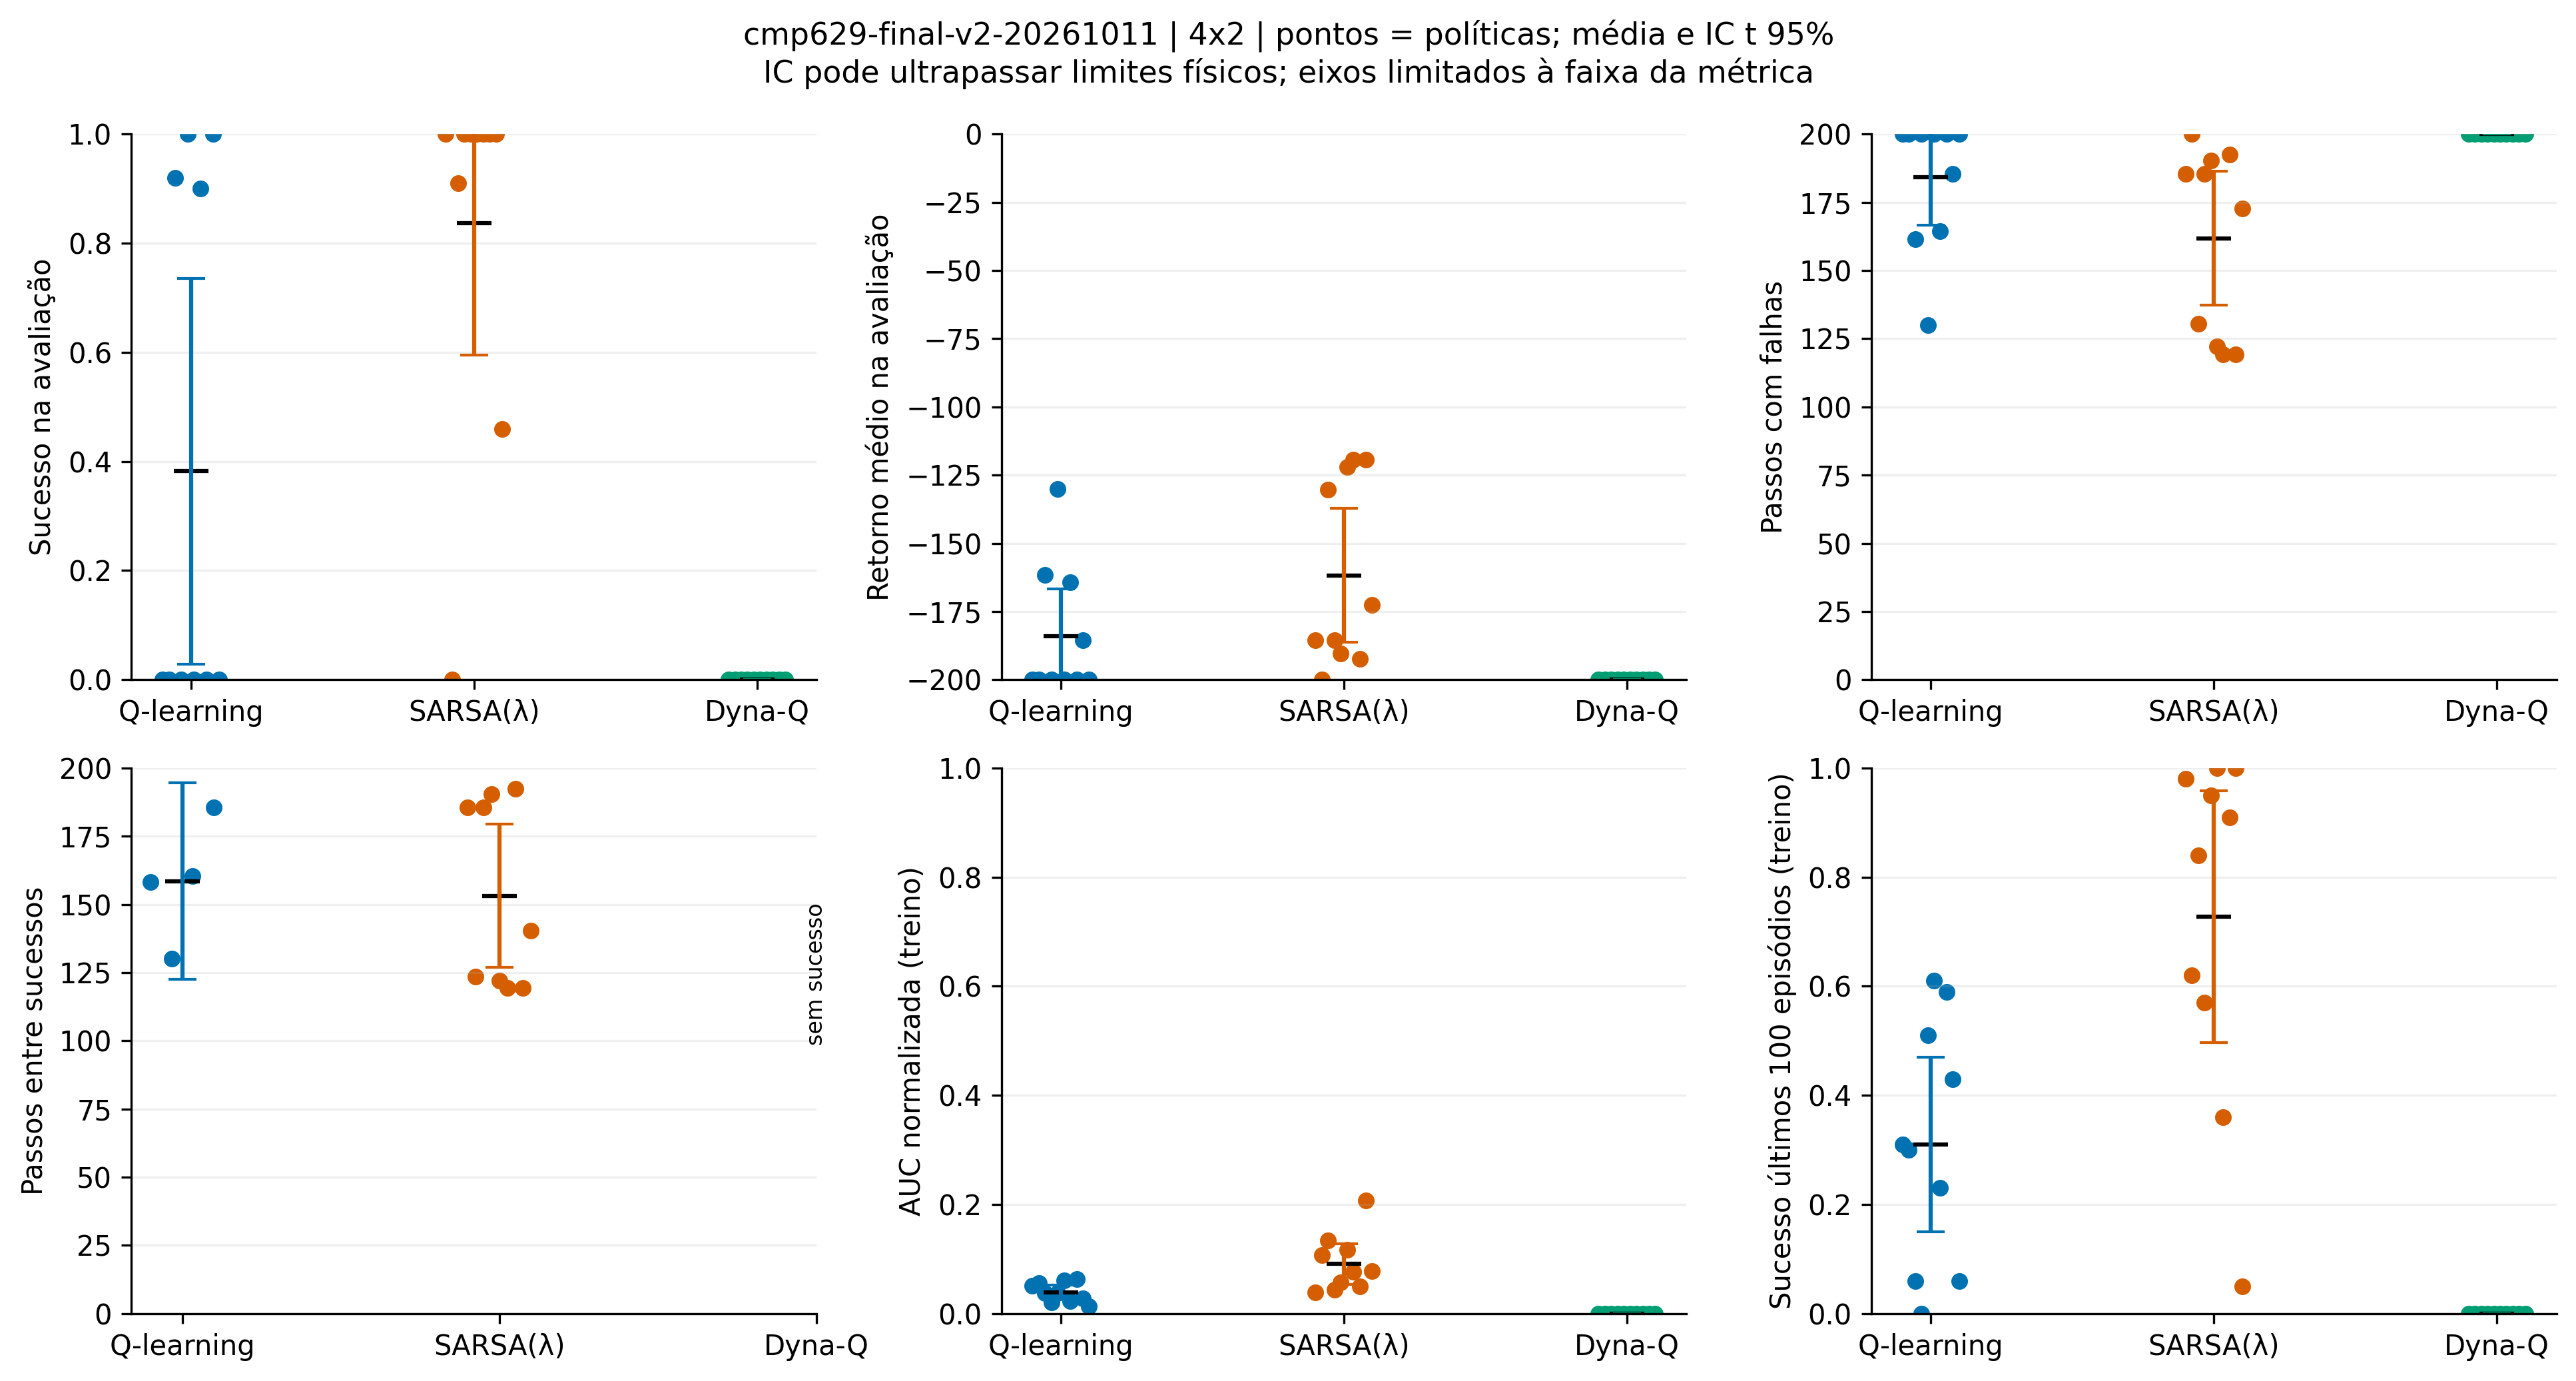

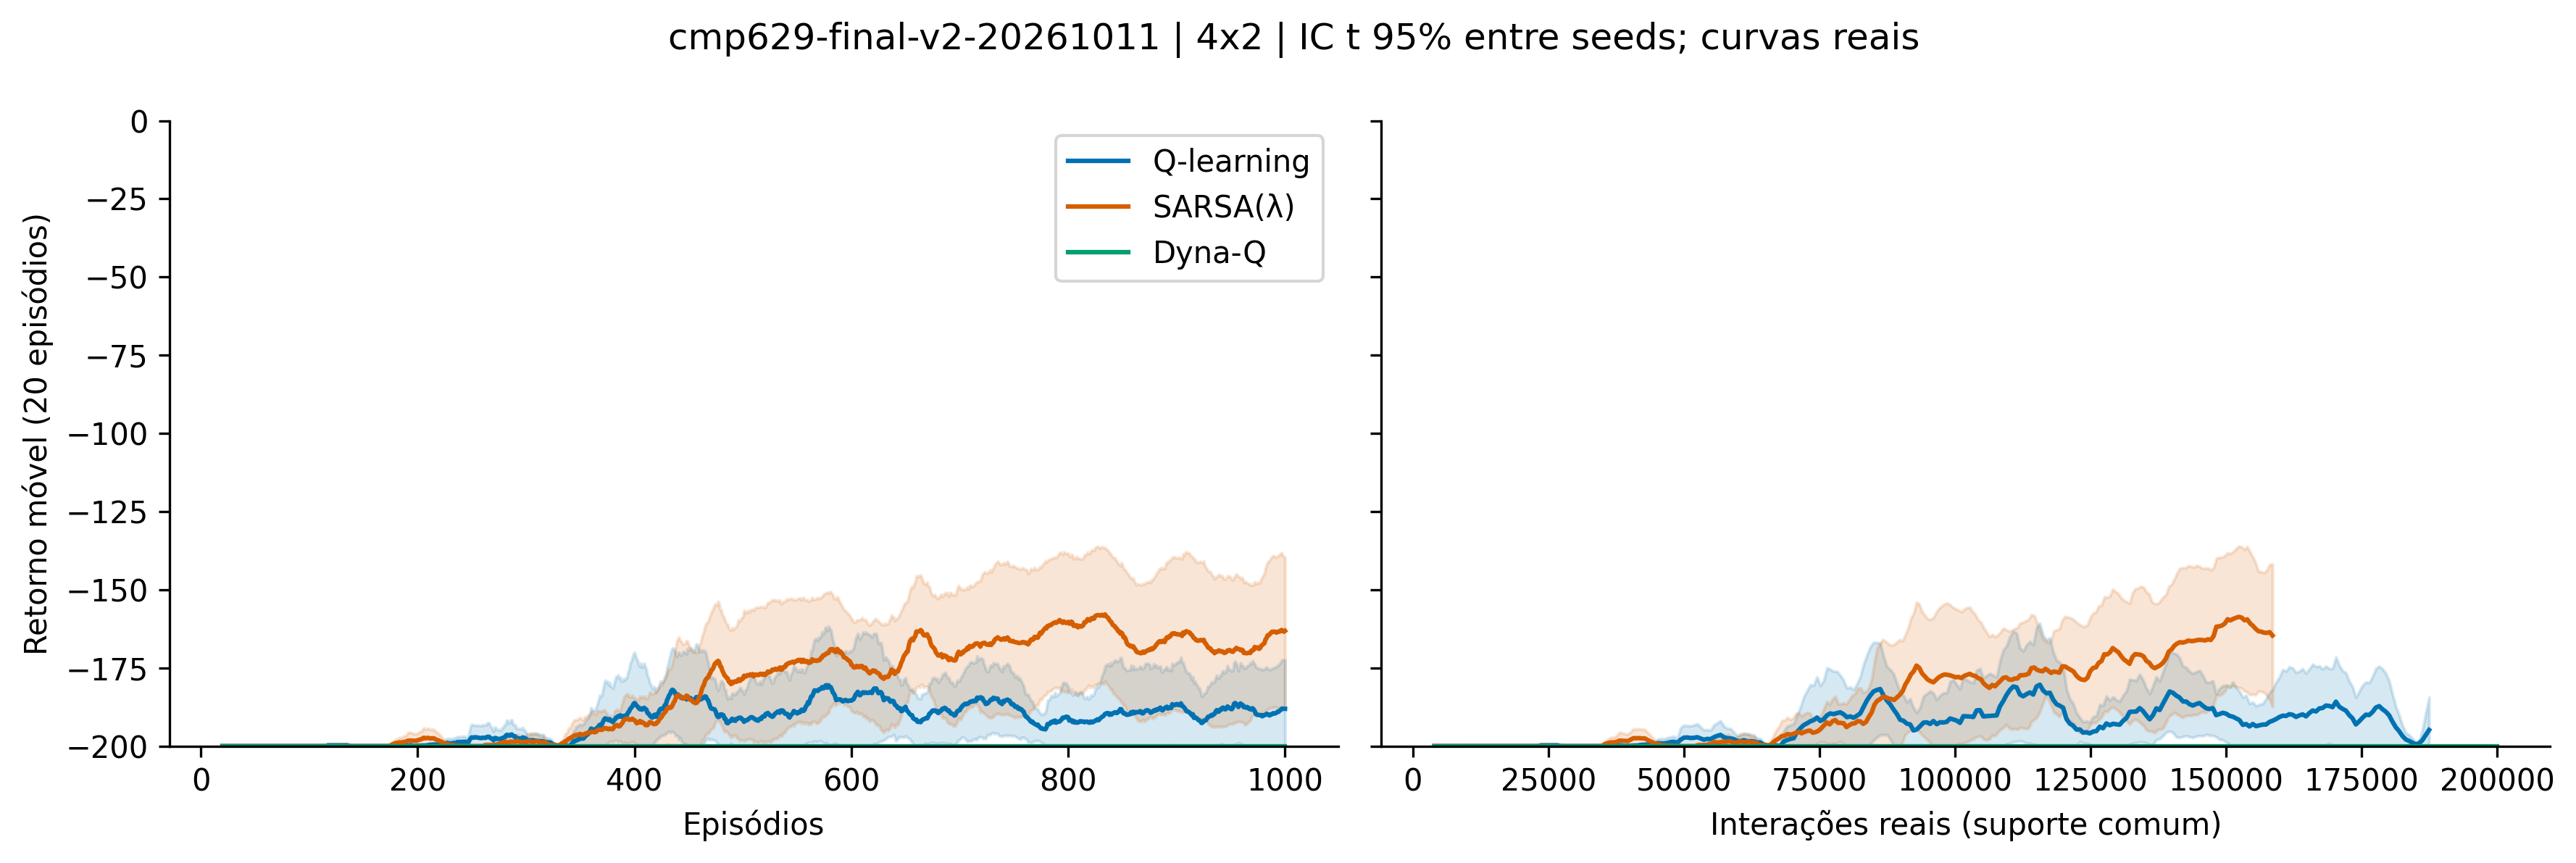

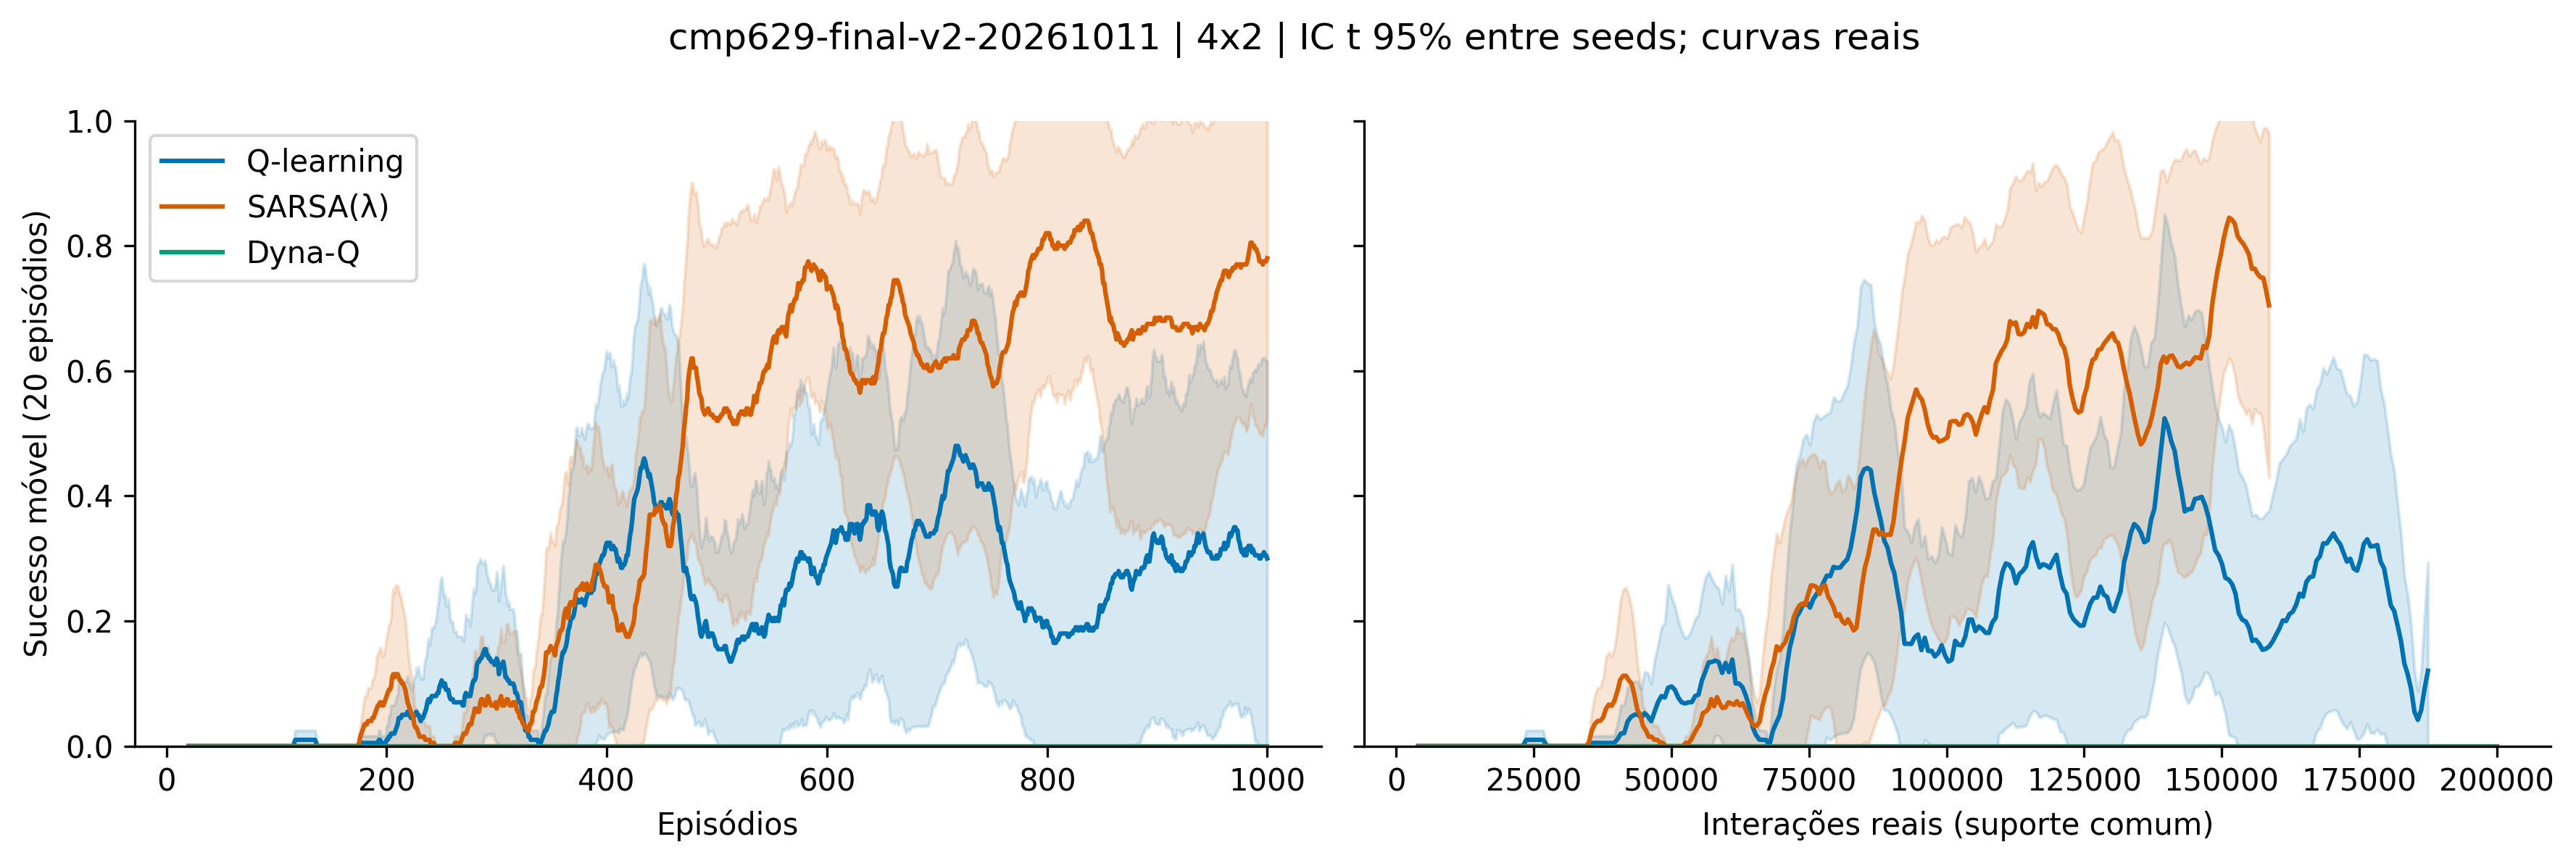

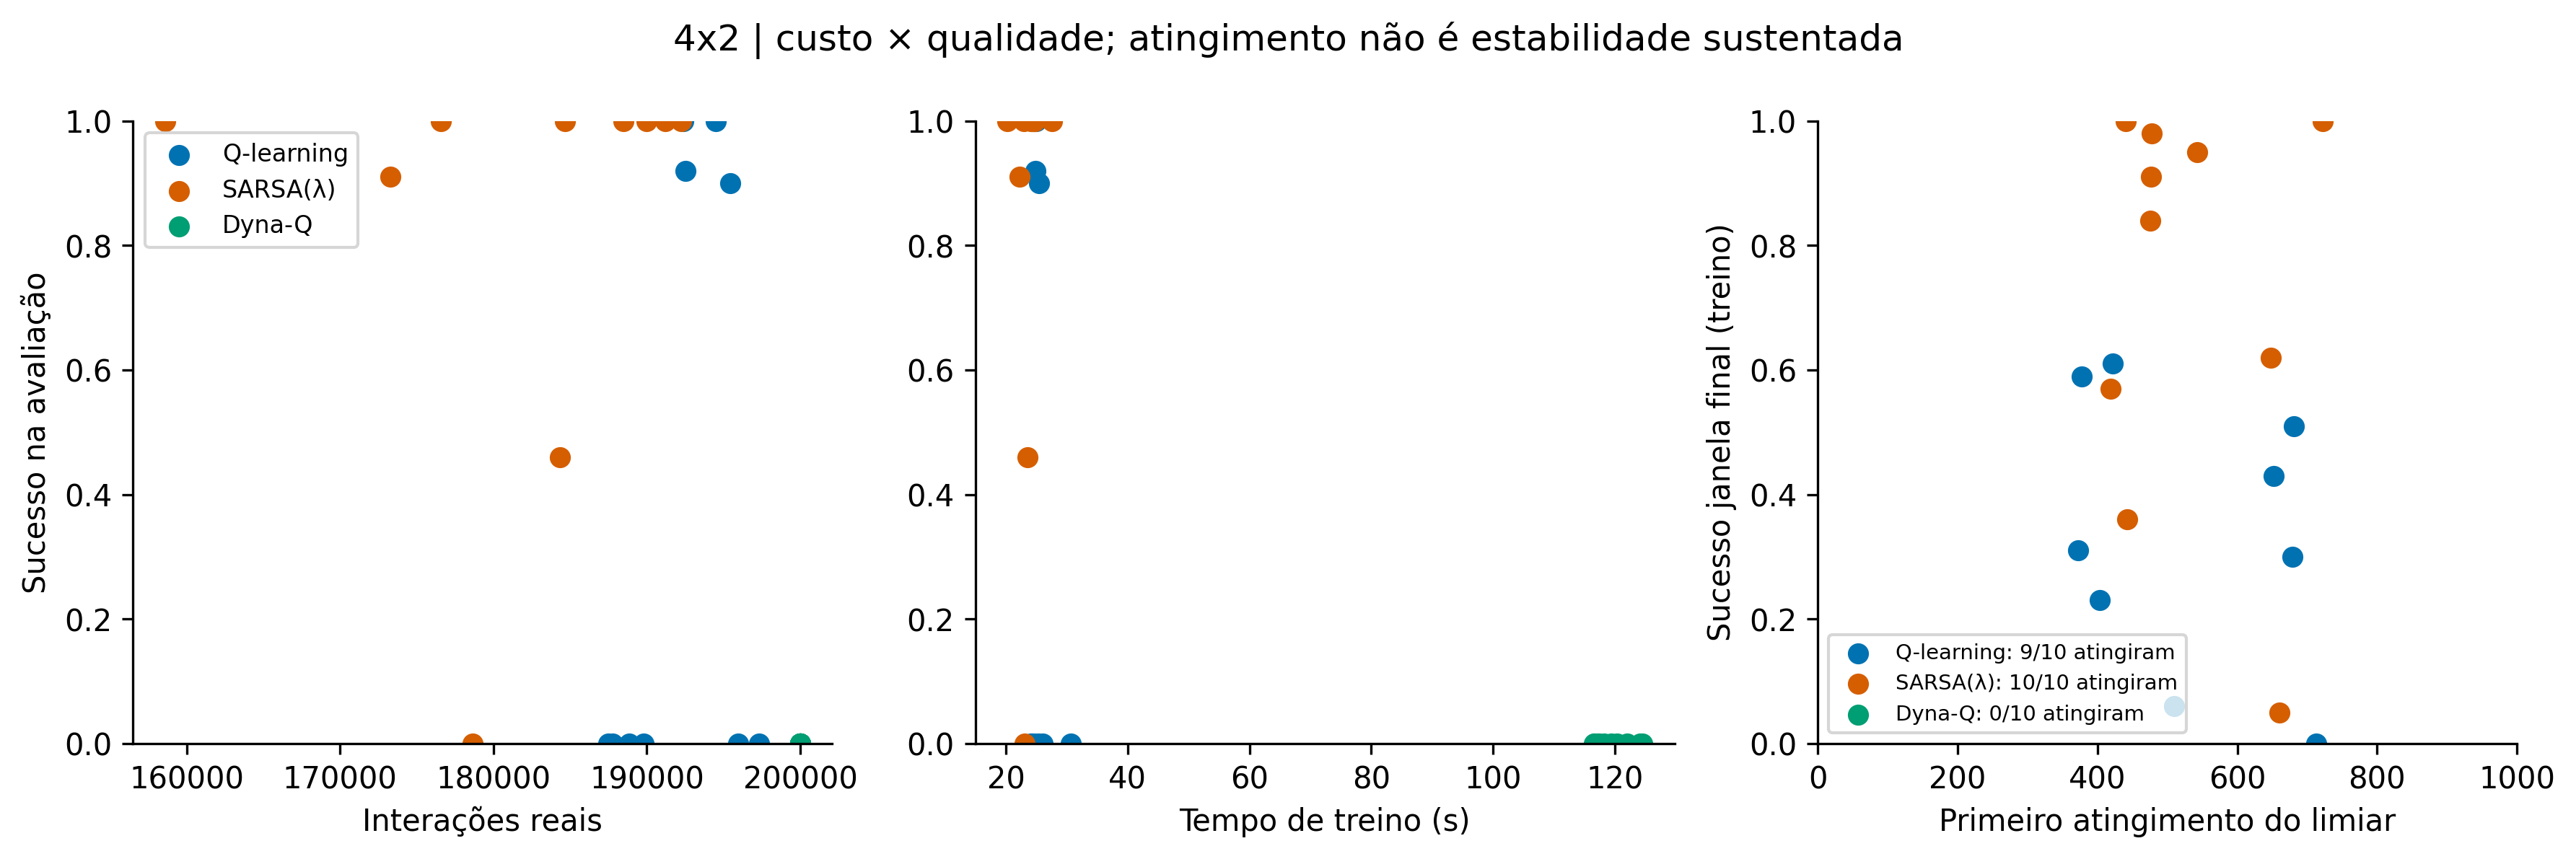

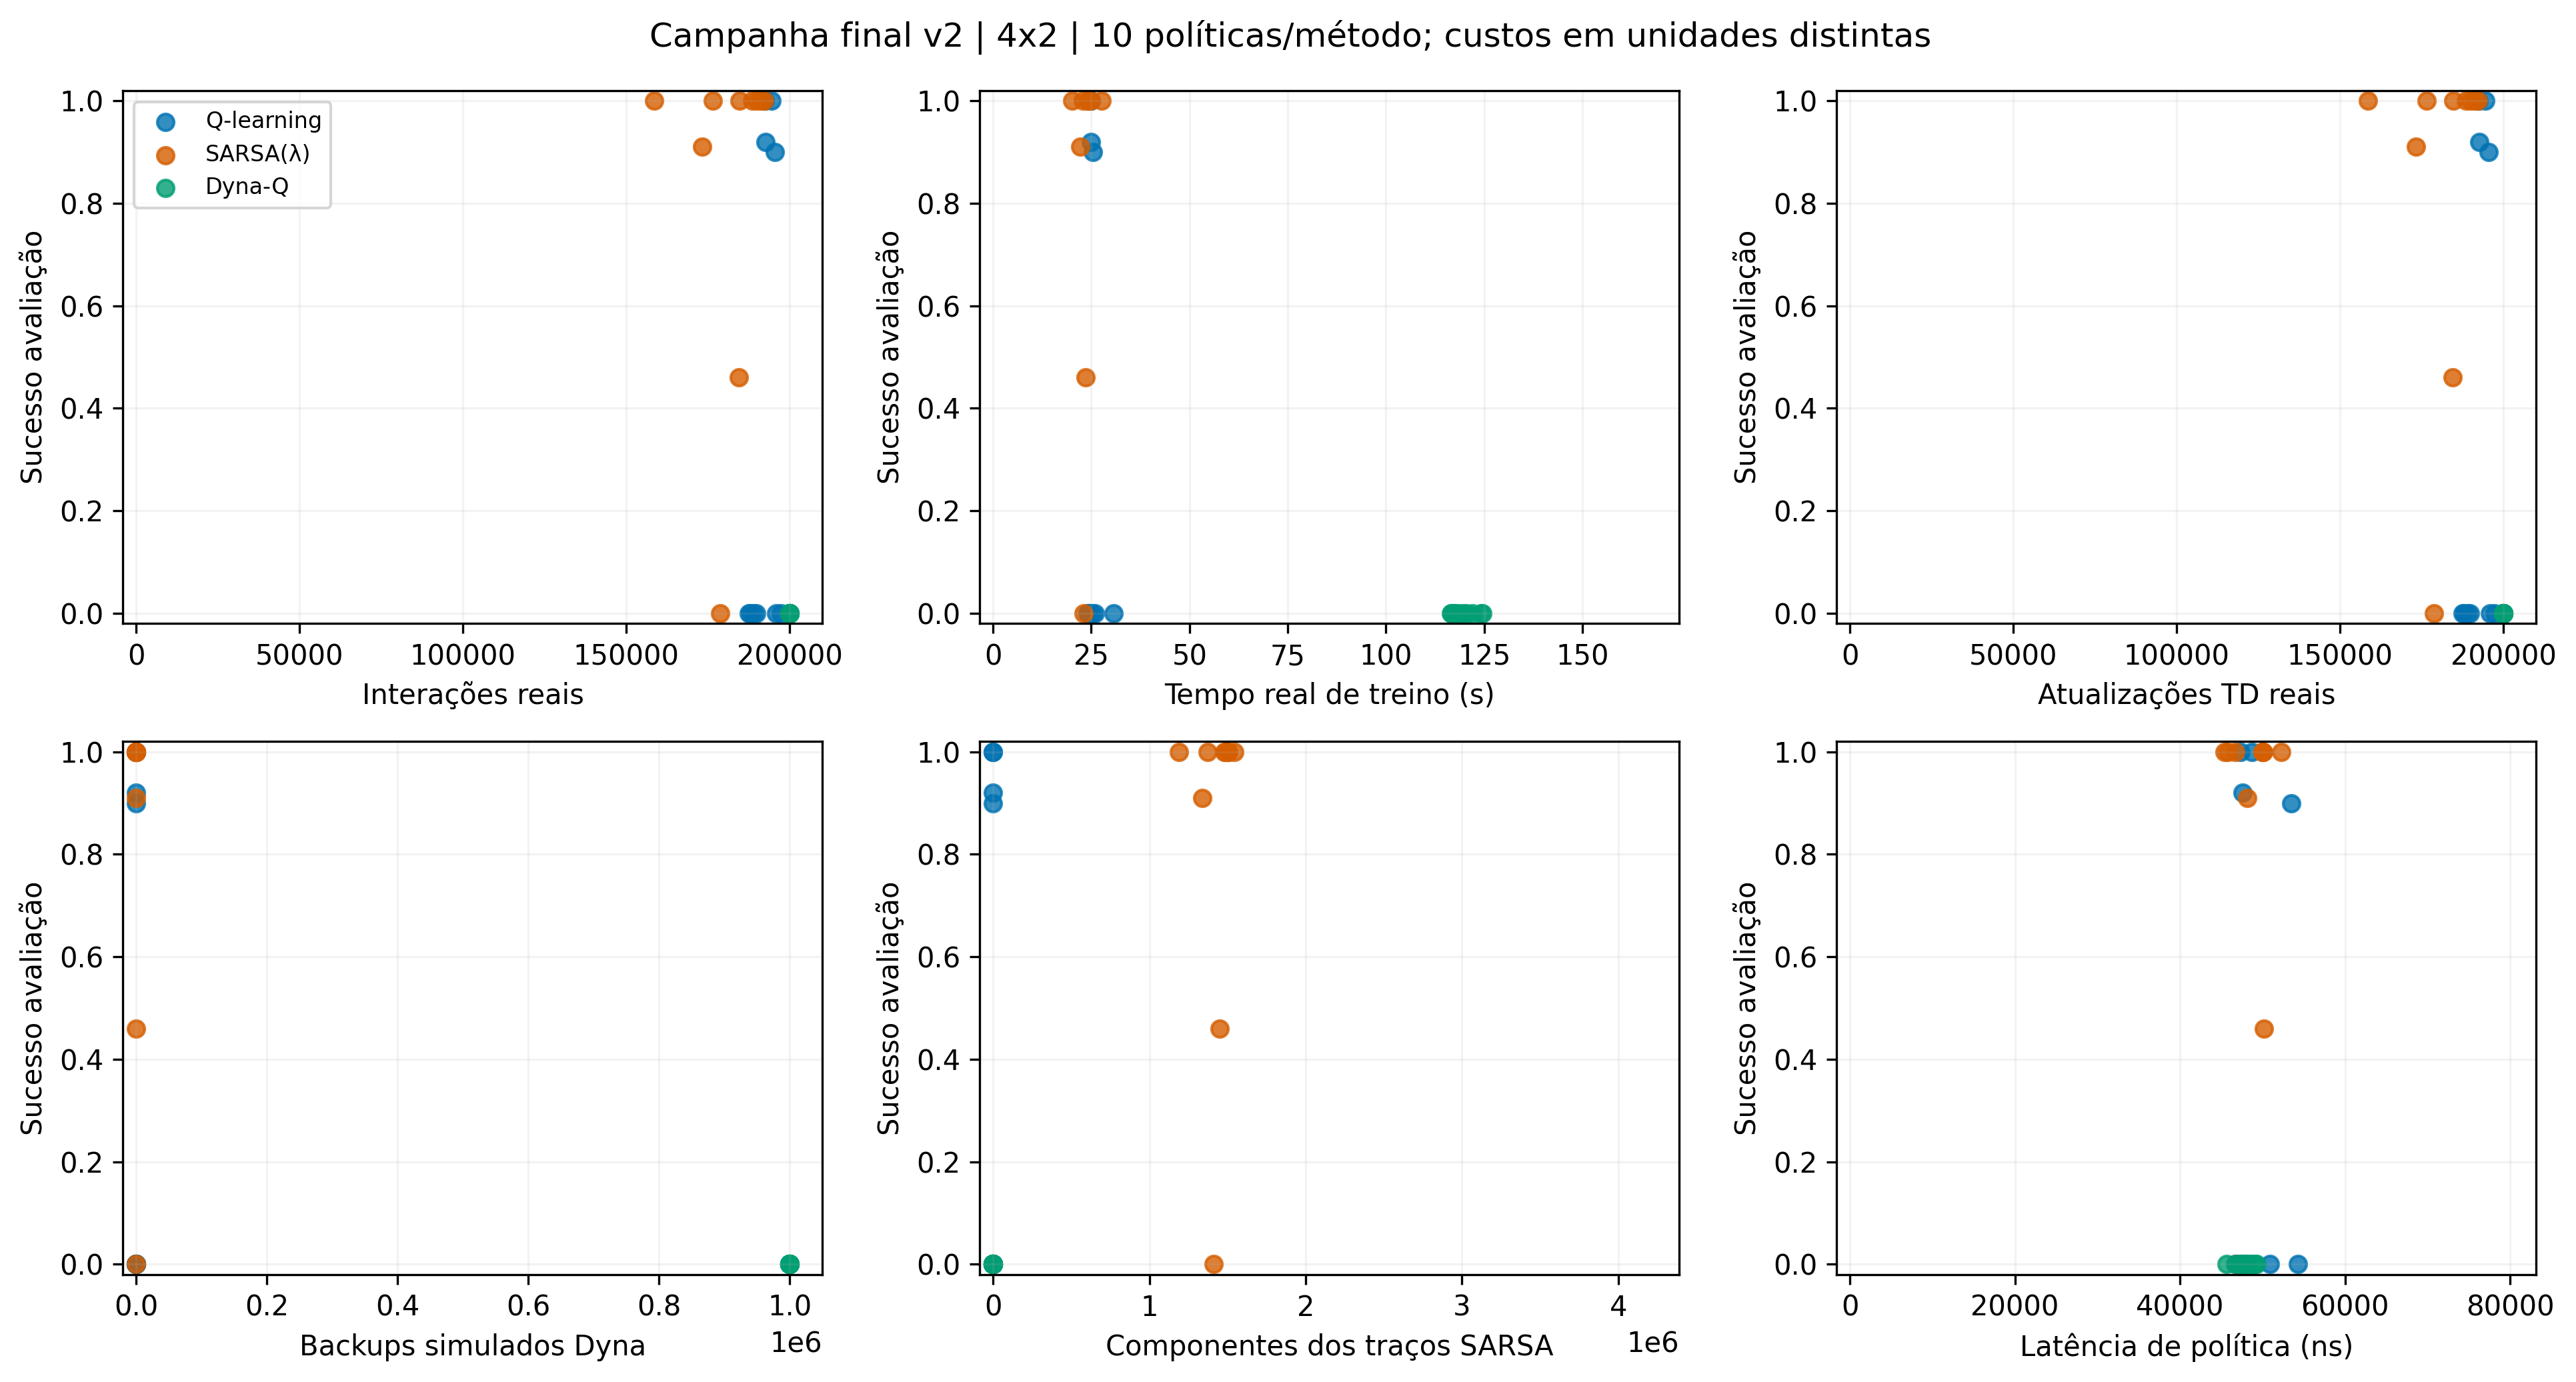

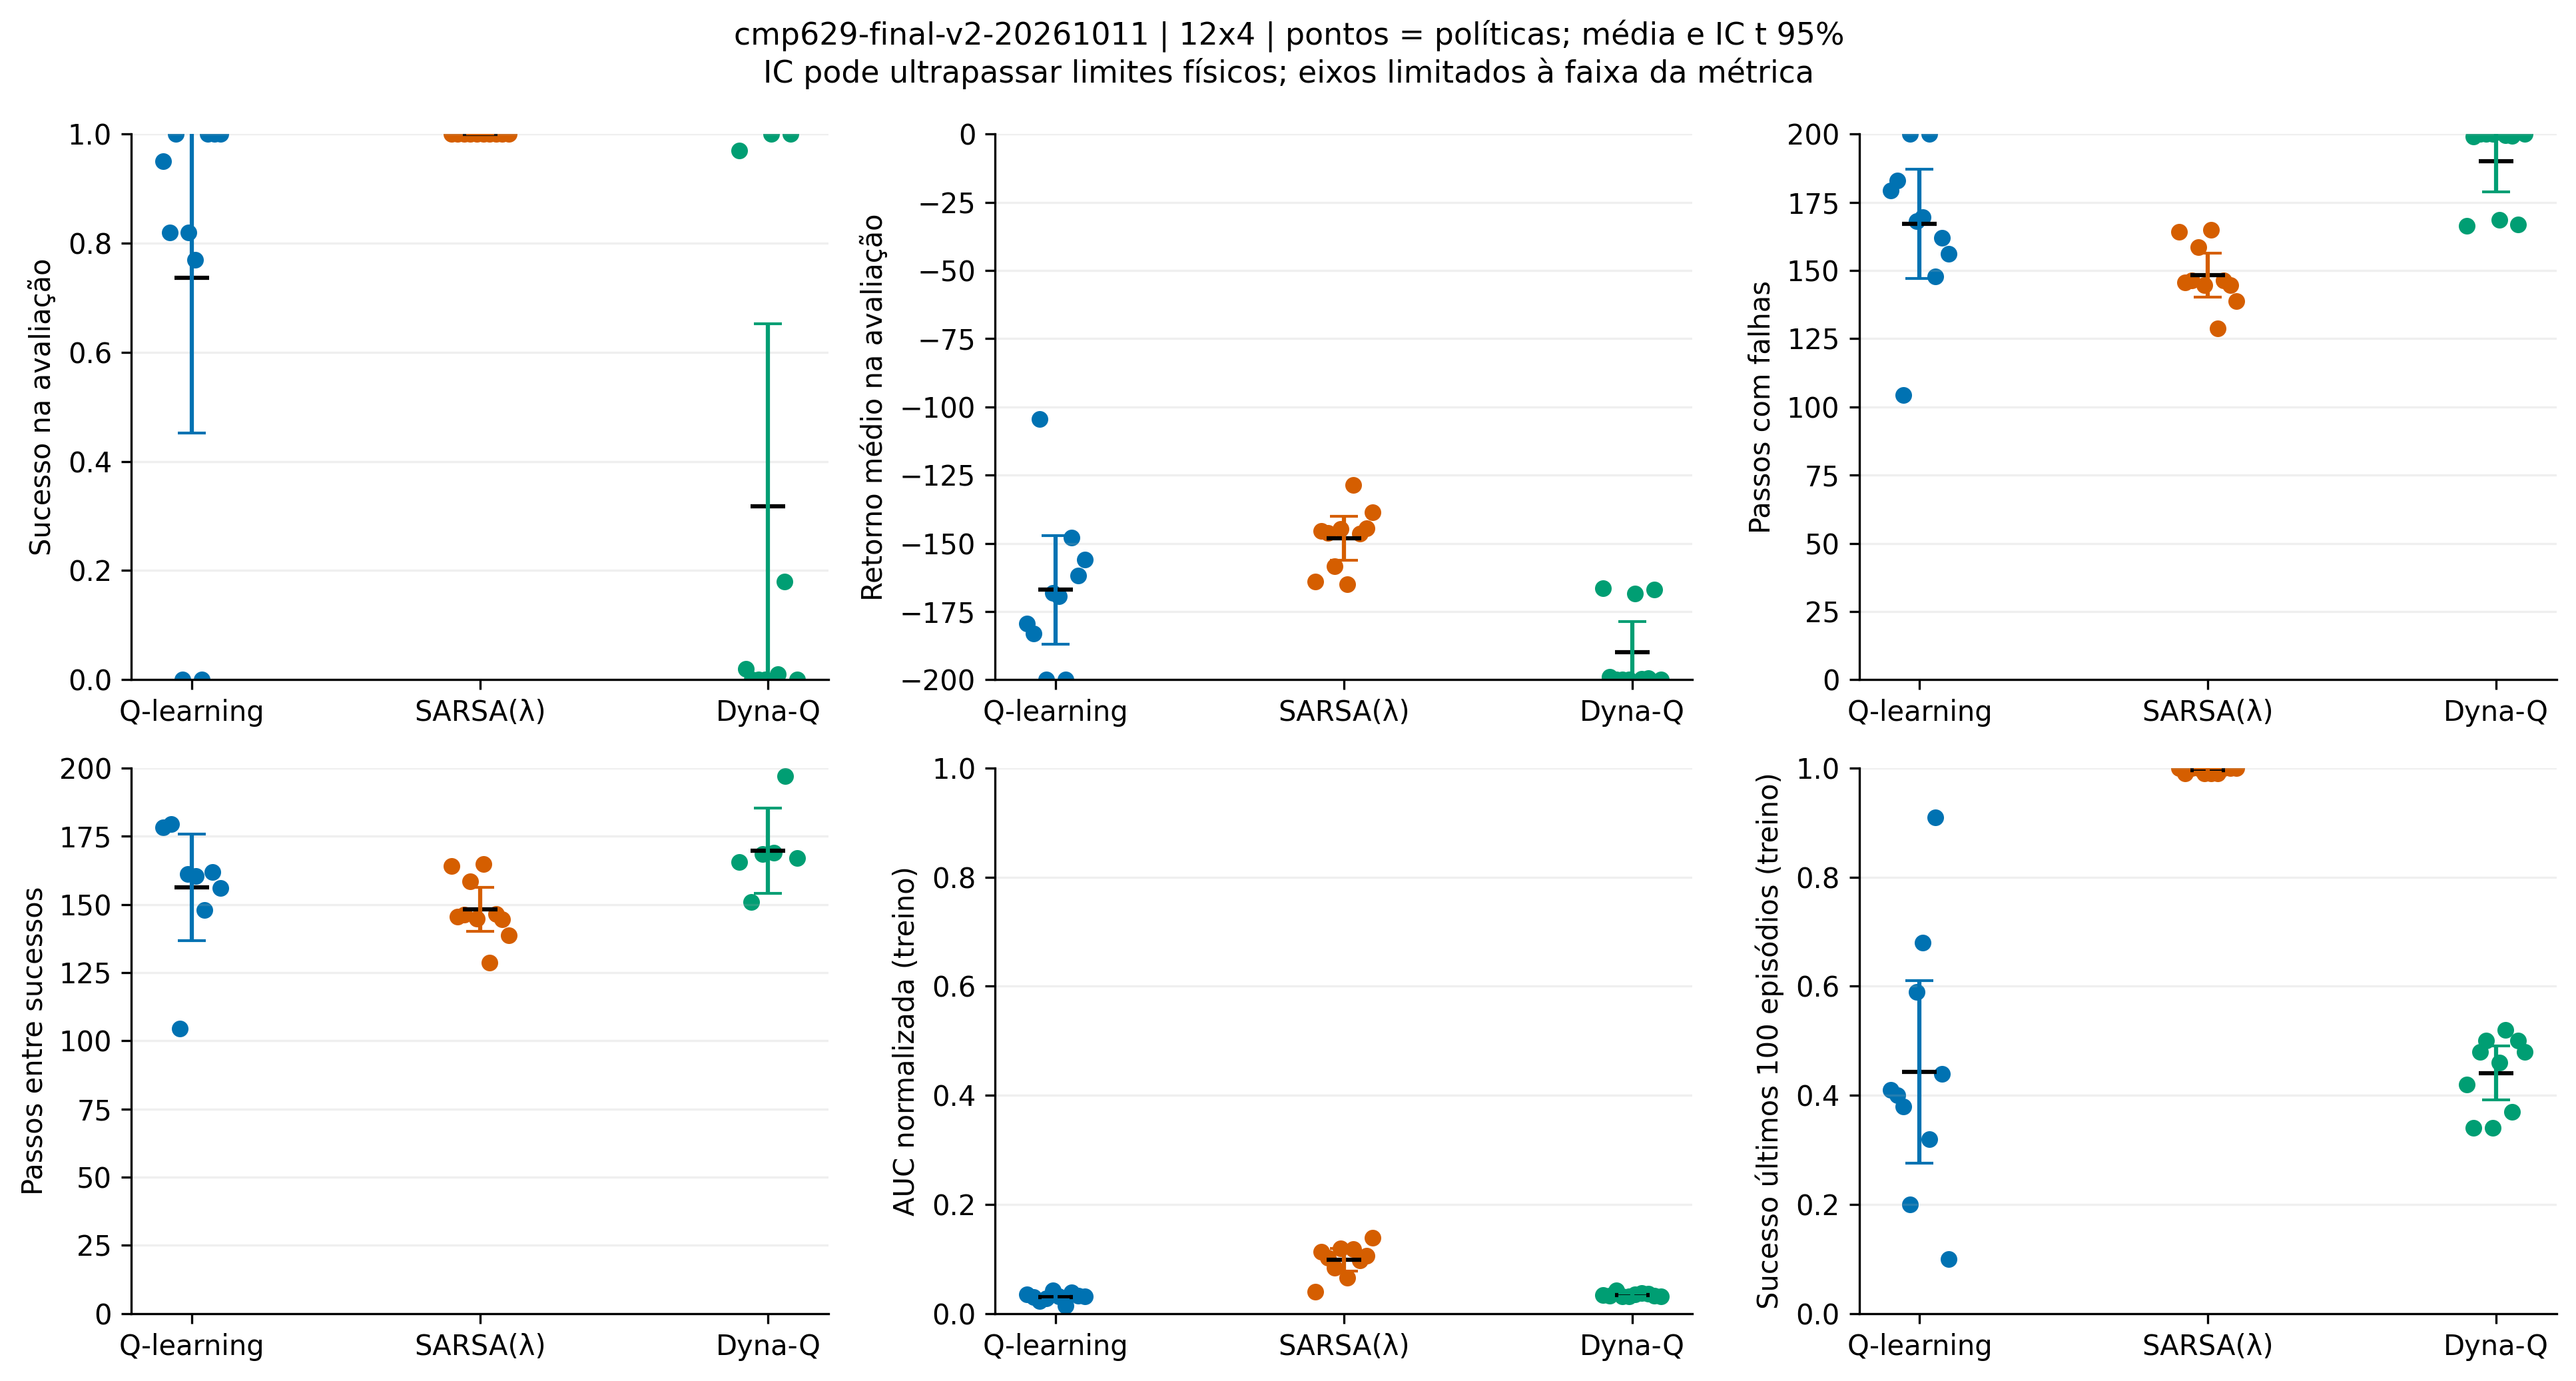

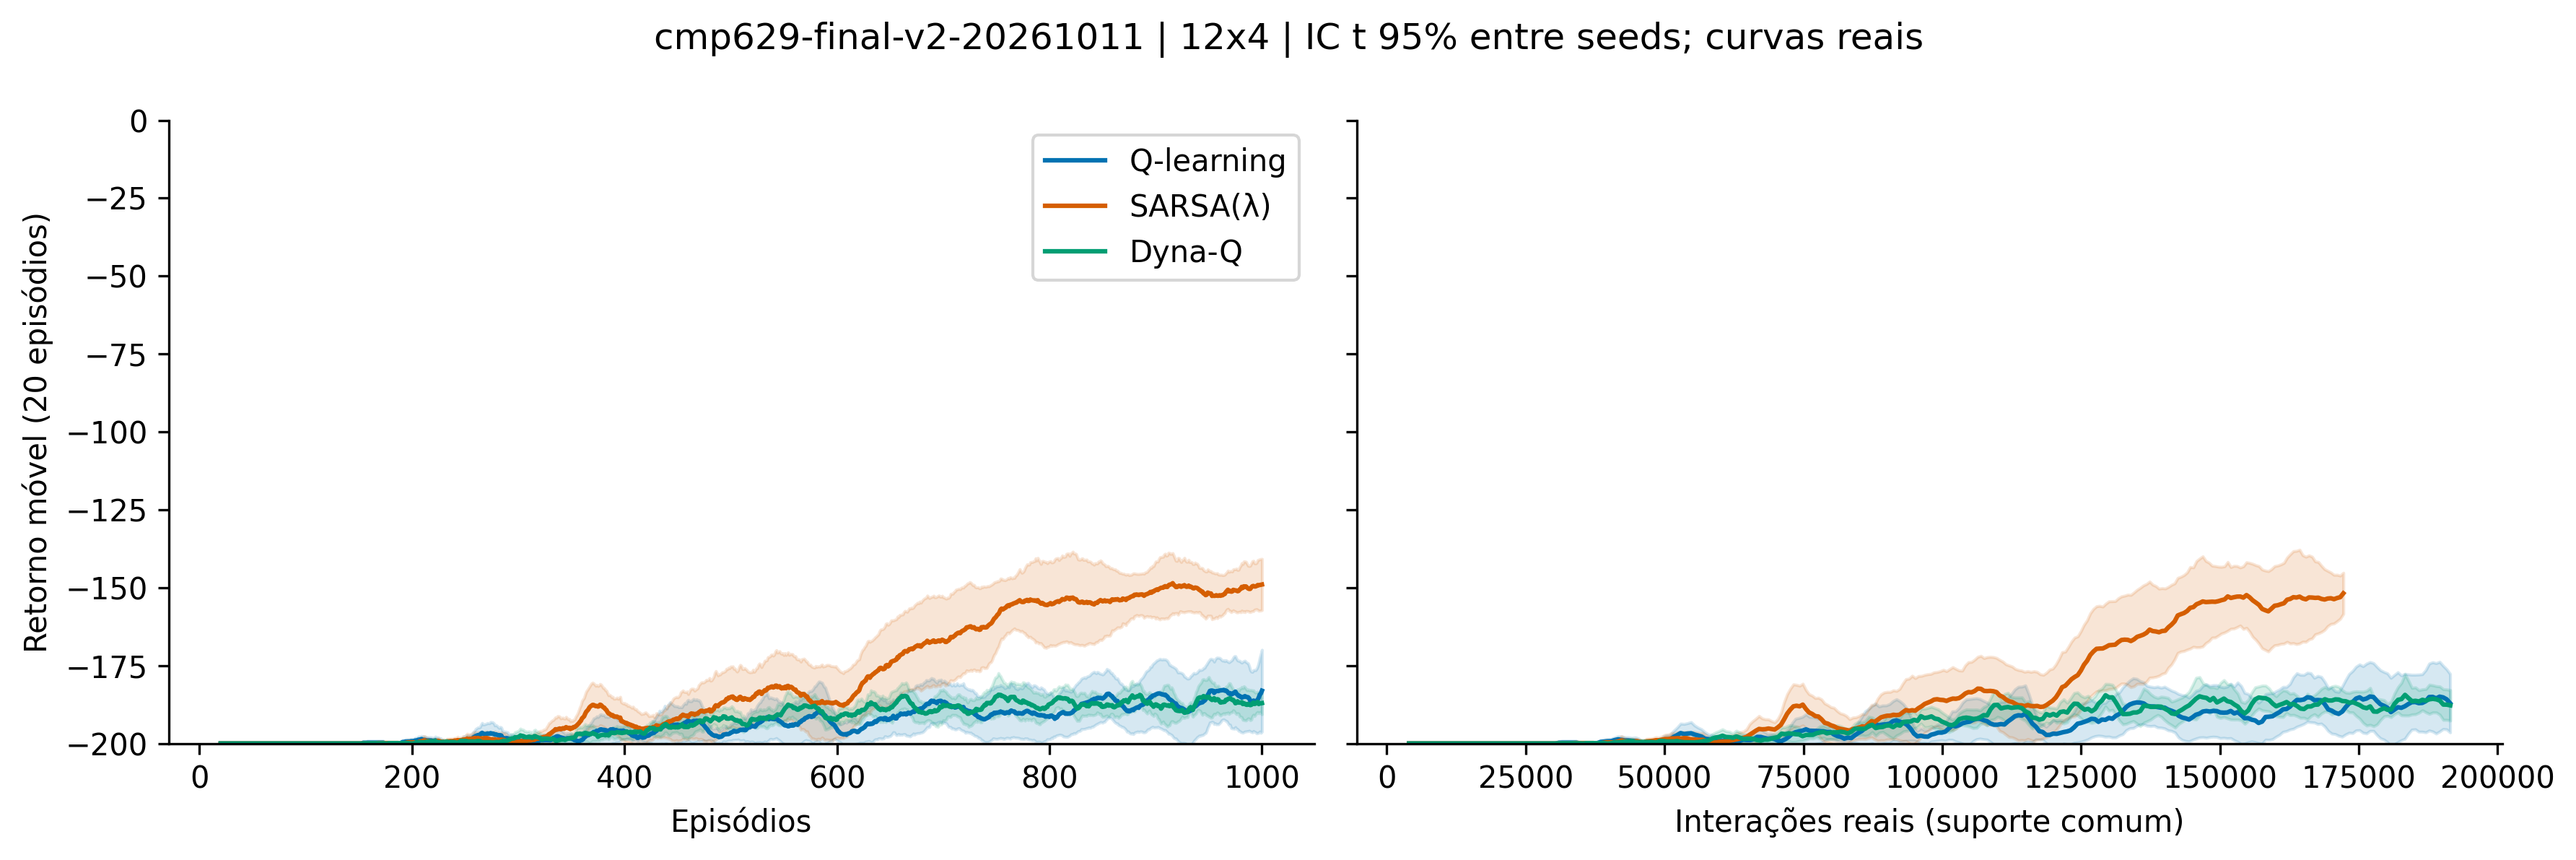

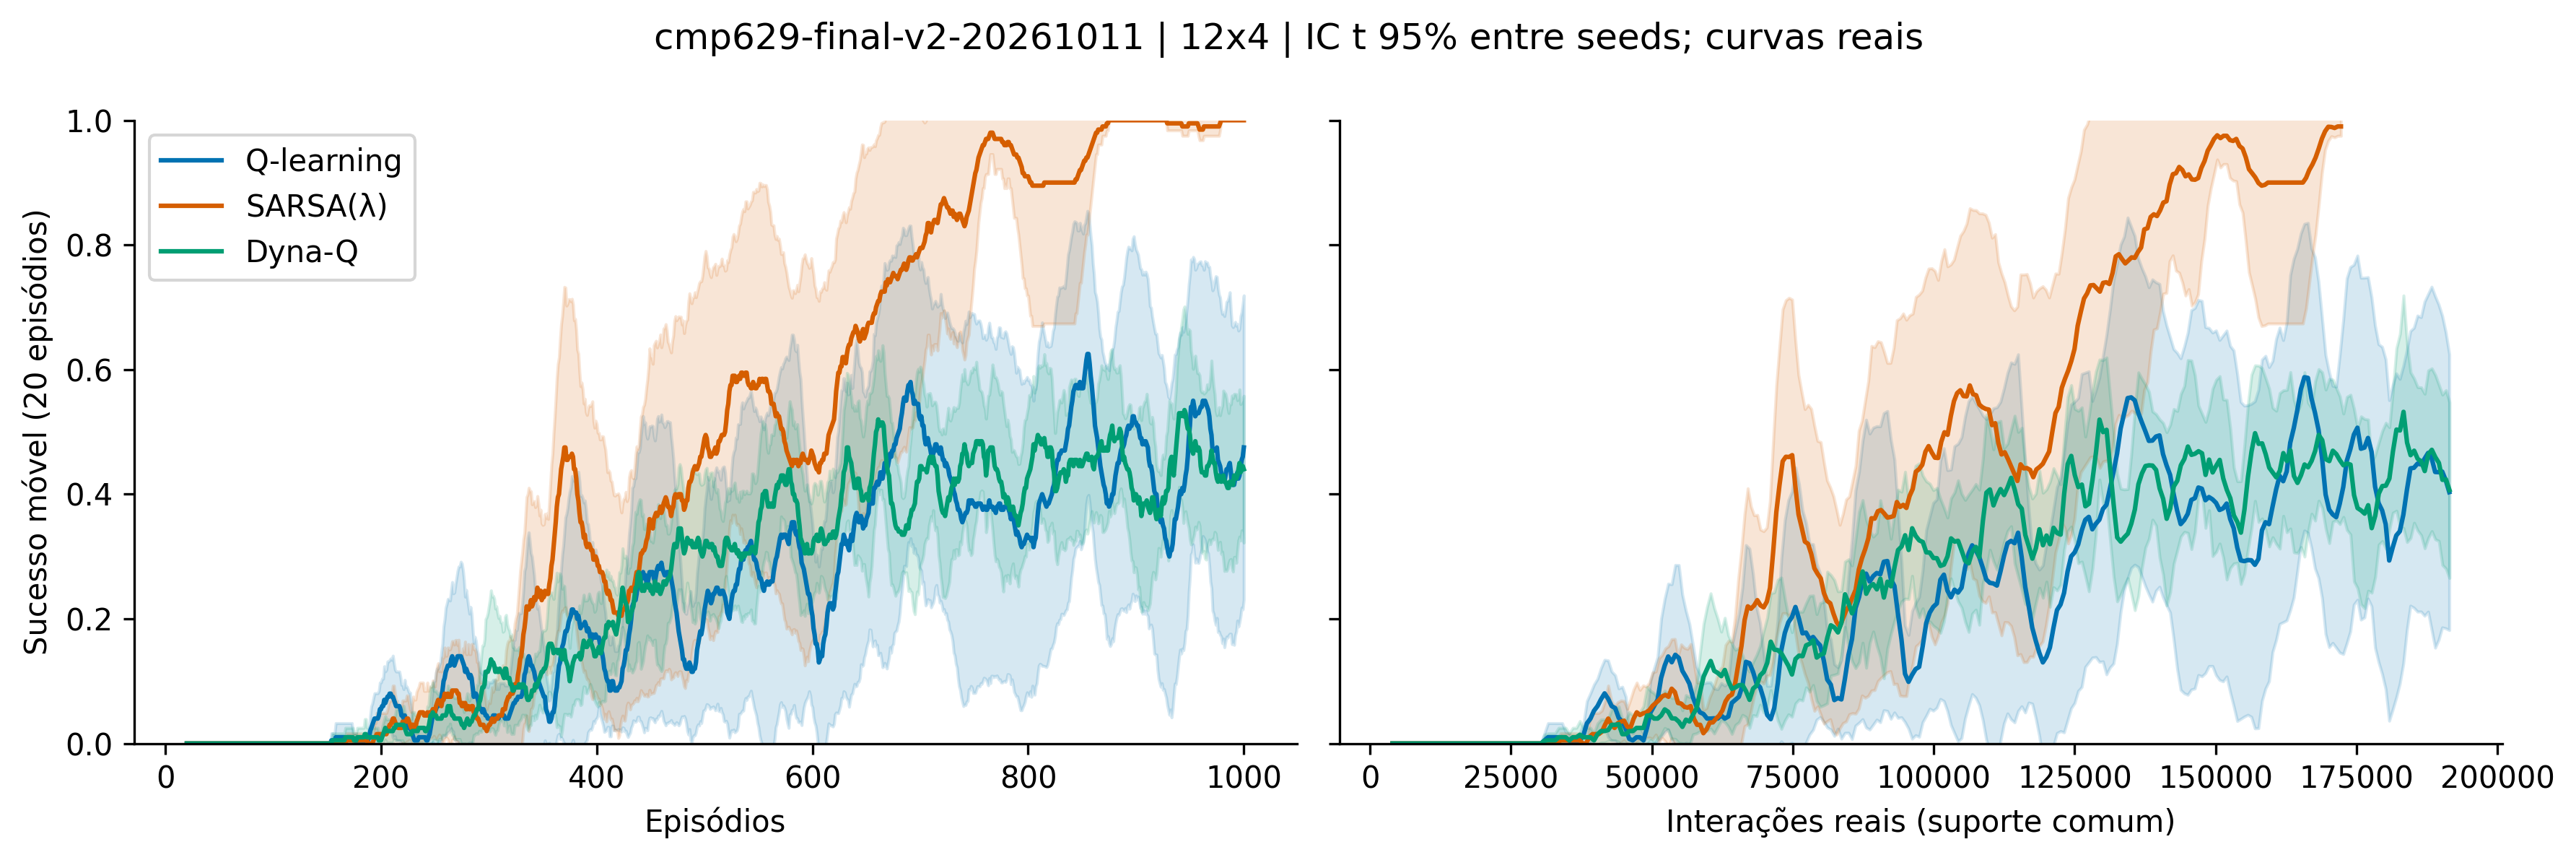

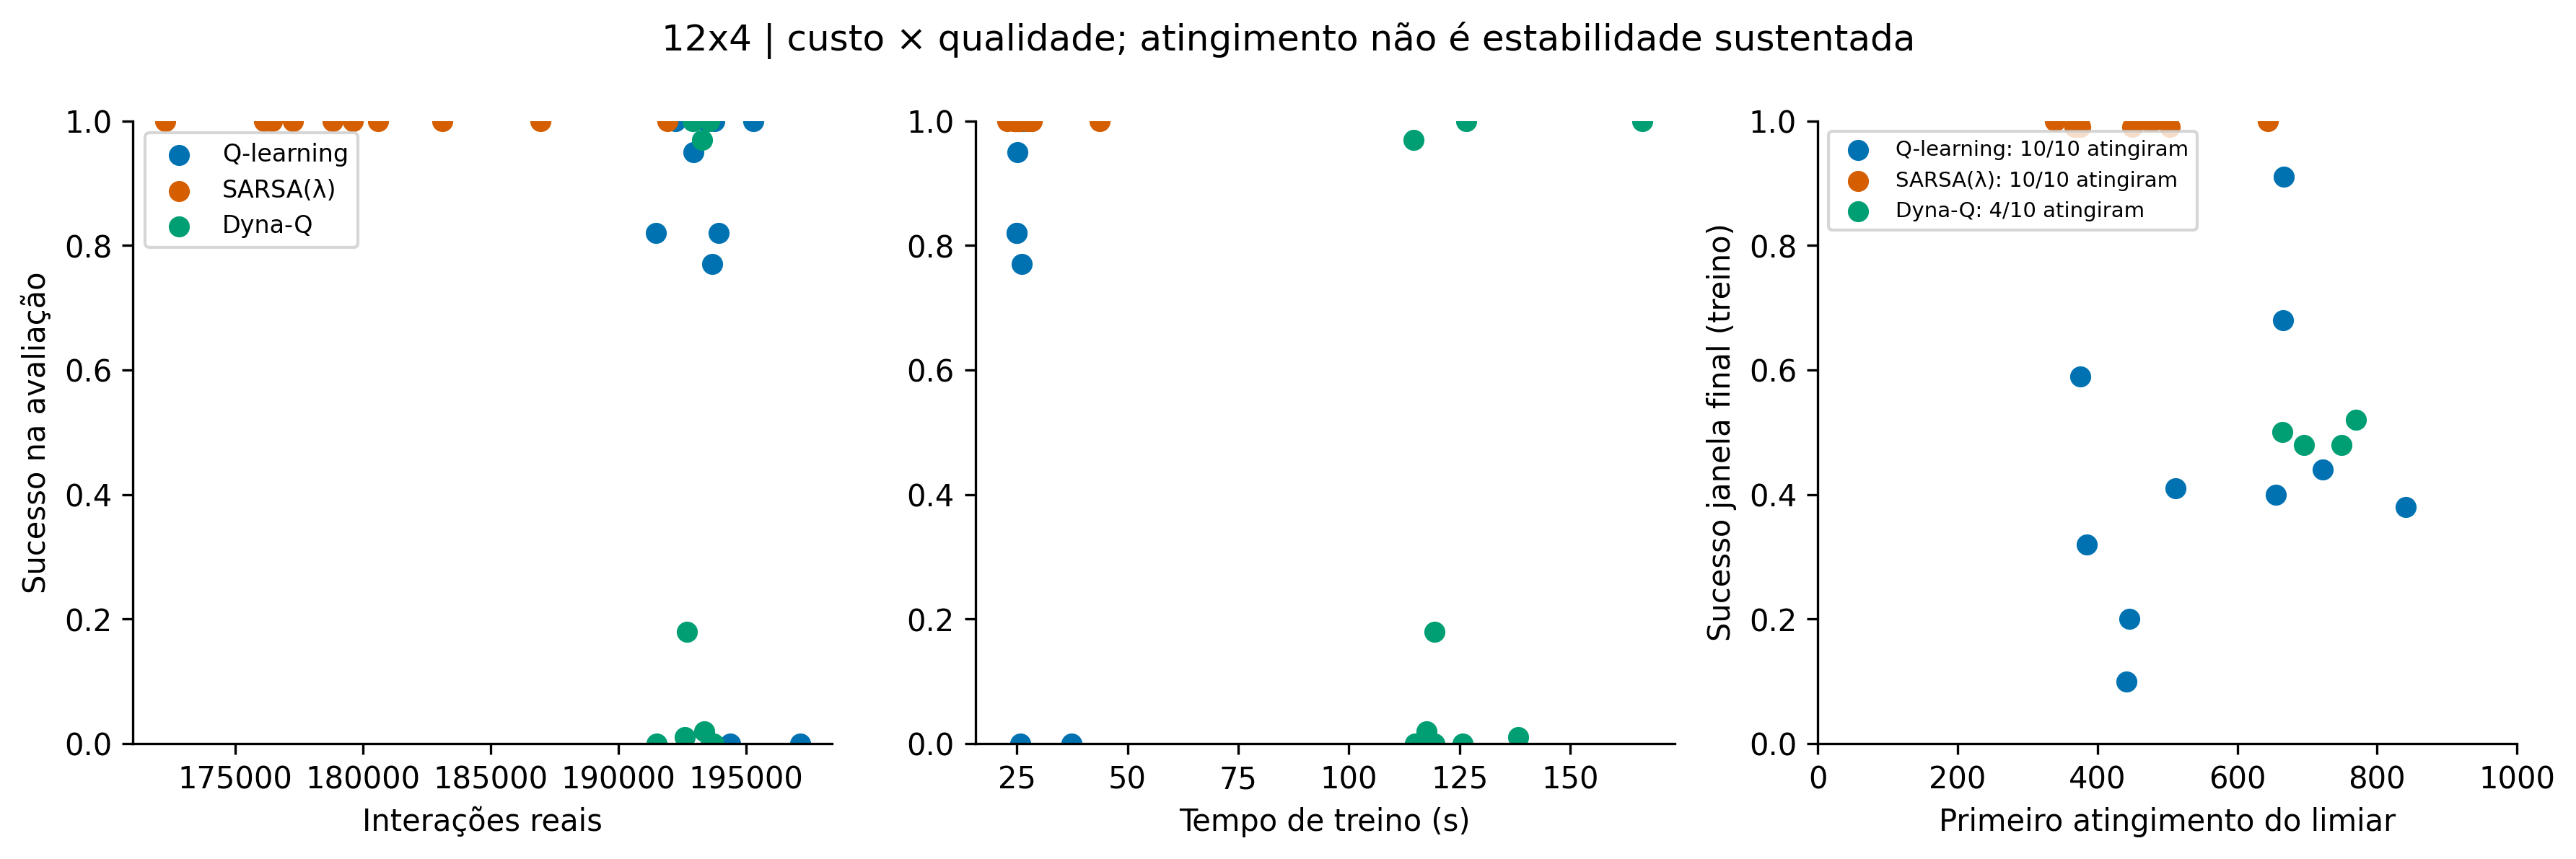

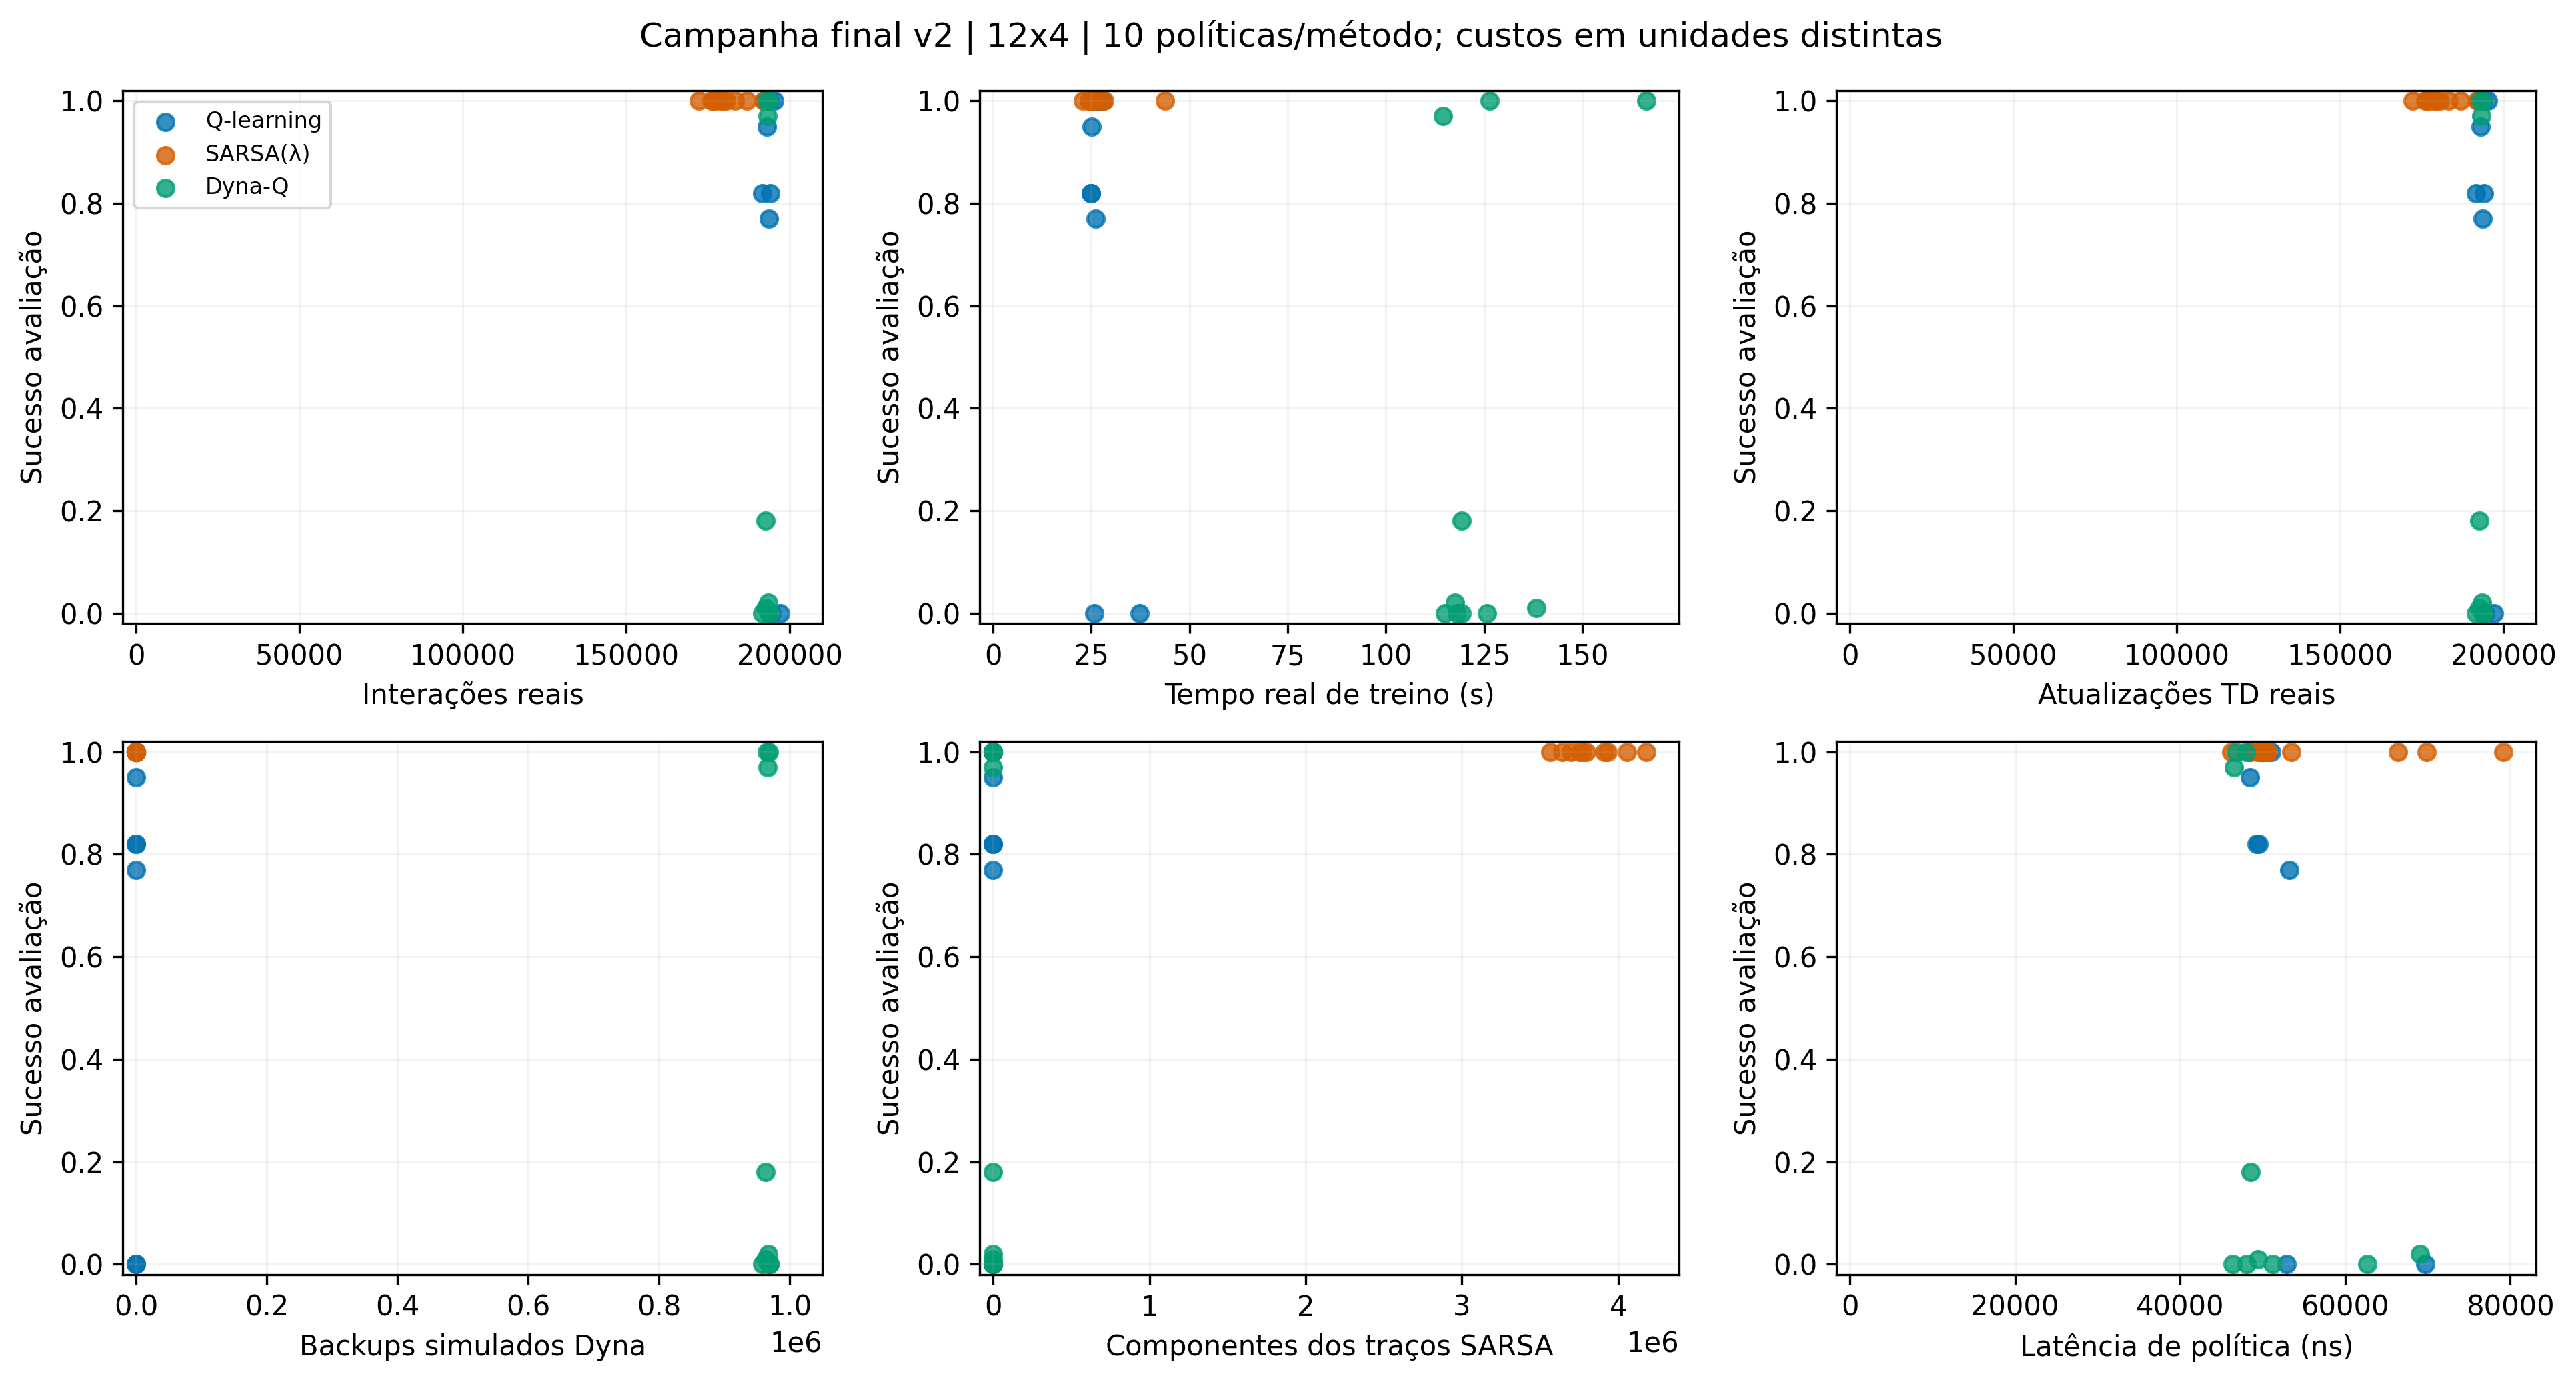

In [3]:
for disc in ("4x2","12x4"):
    for figure in ("painel", "episode_returns", "episode_successes", "custos_limiar", "custos_separados"):
        data=verified(f"figuras/final_v2/{figure}_{disc}.png")
        (OUT/f"final_{figure}_{disc}.png").write_bytes(data)
        display(Image(data,width=1050))

### Políticas, trajetórias e animações finais

Menor seed de treino (3100), reset 900000 previamente fixado, mesmas condições iniciais entre métodos. Não é seleção da melhor política. Mapas Q usam as fronteiras físicas das células; −1 na política significa empate. Uma trajetória não estima a taxa média de sucesso.

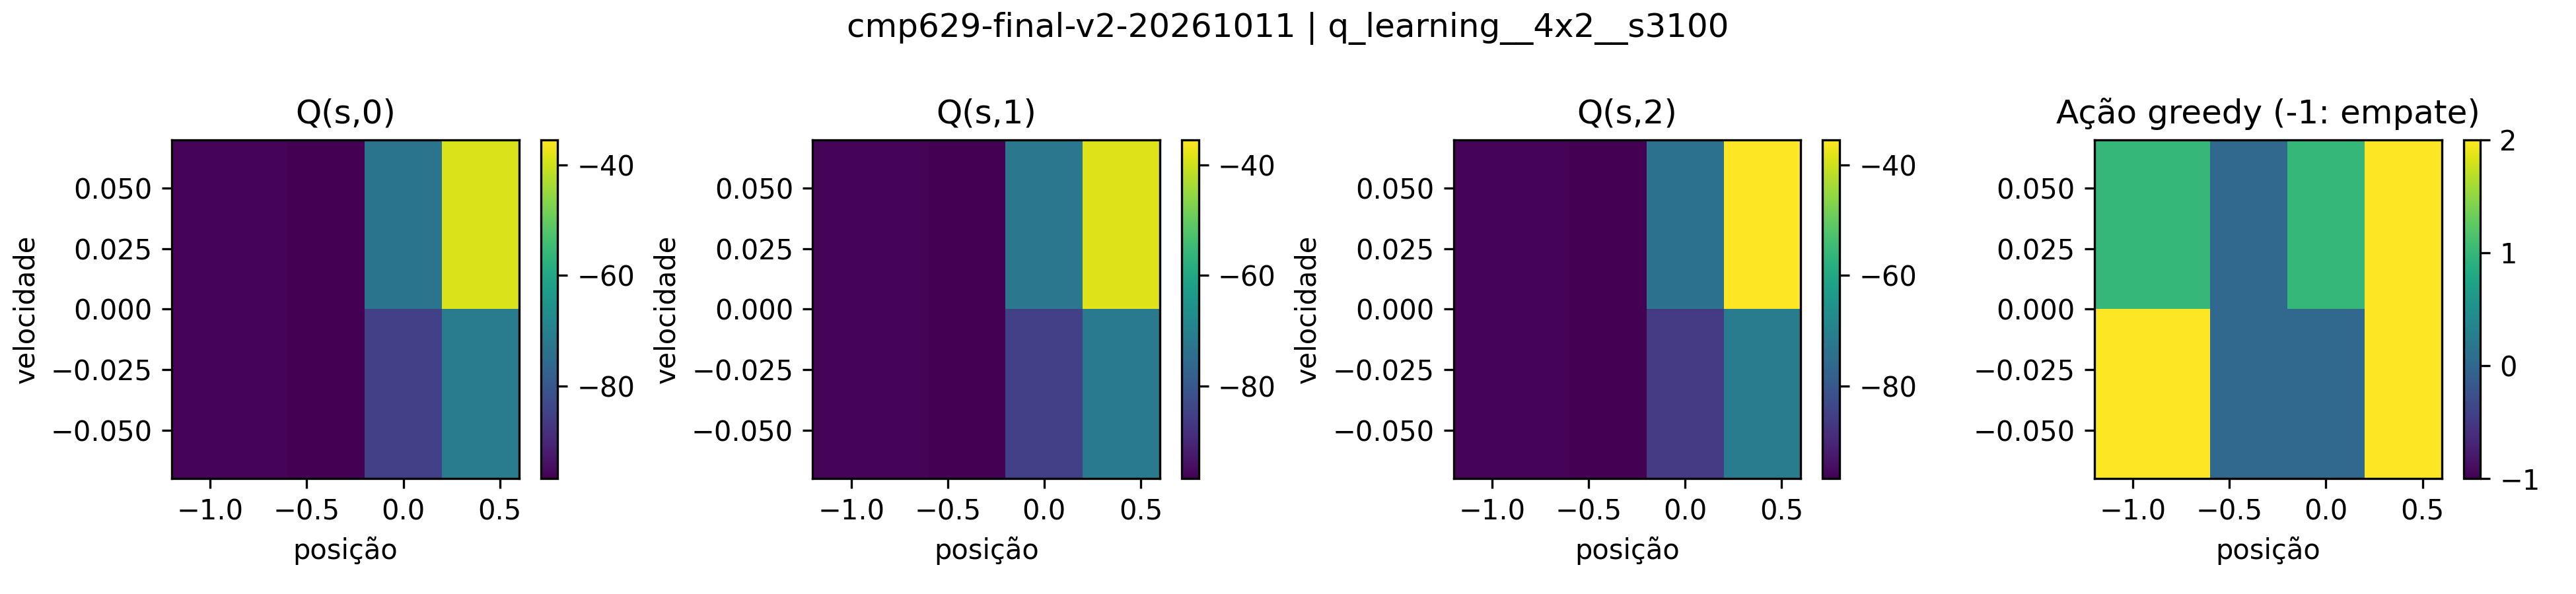

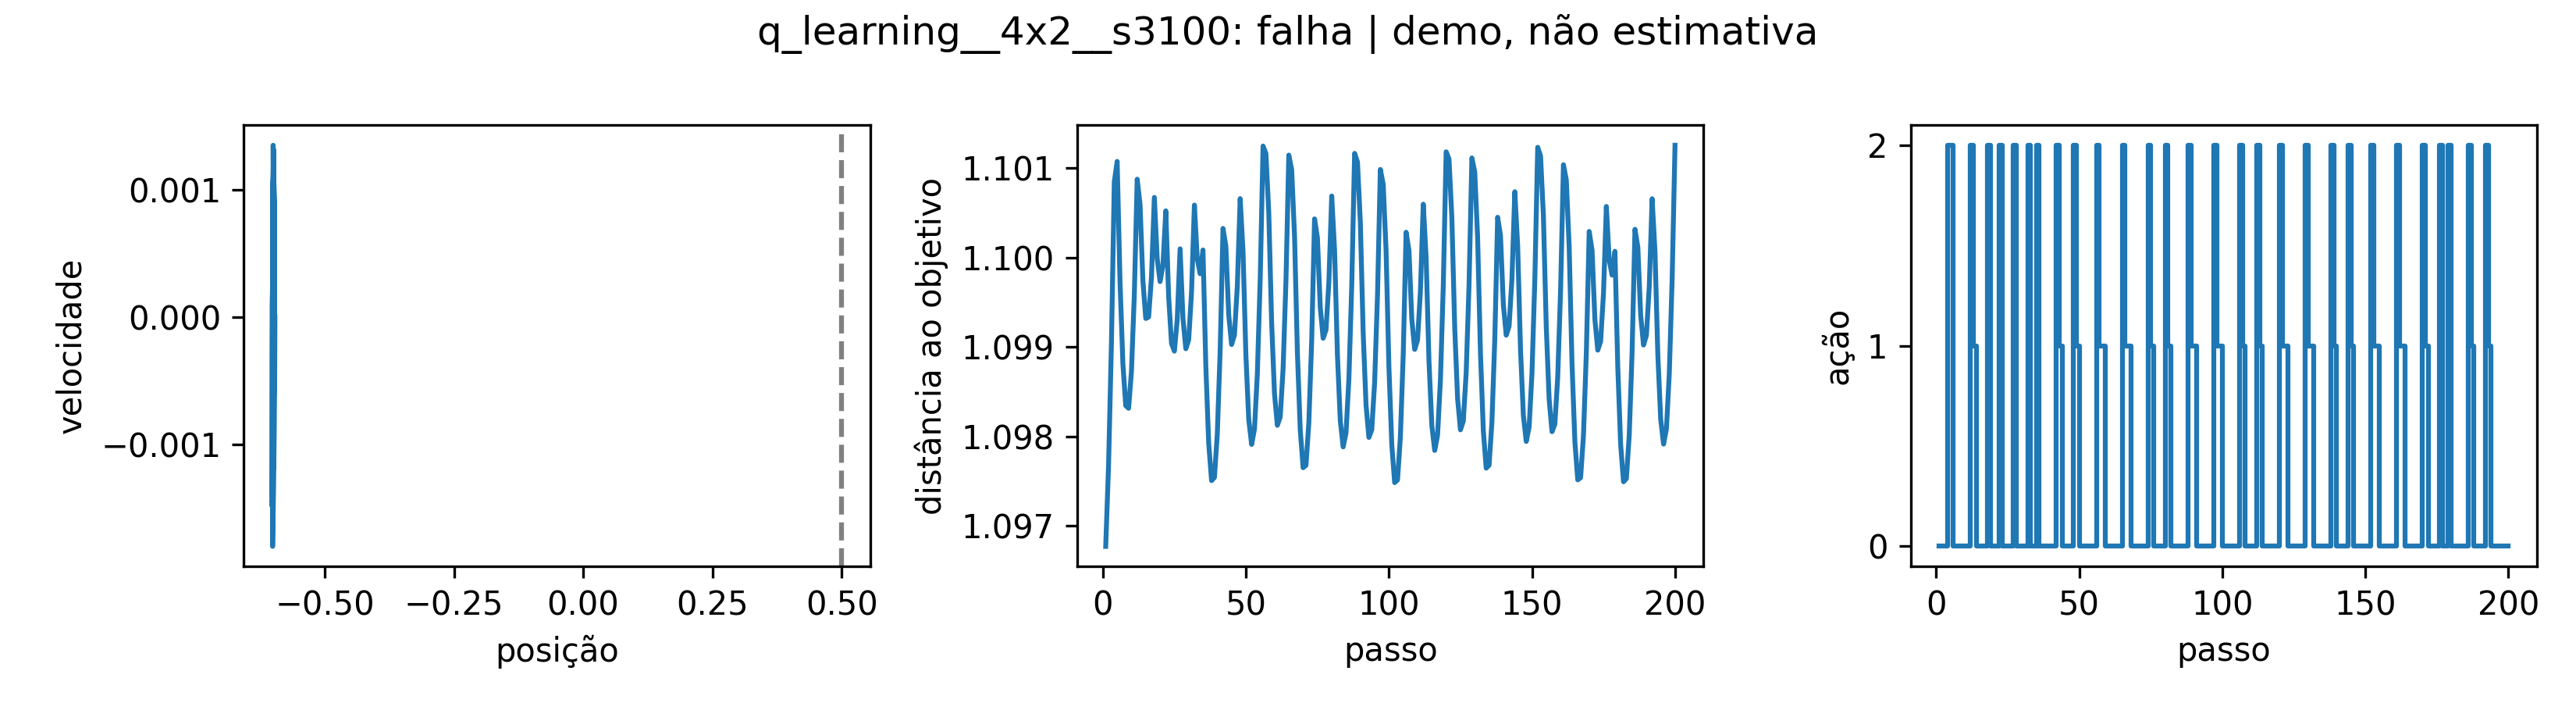

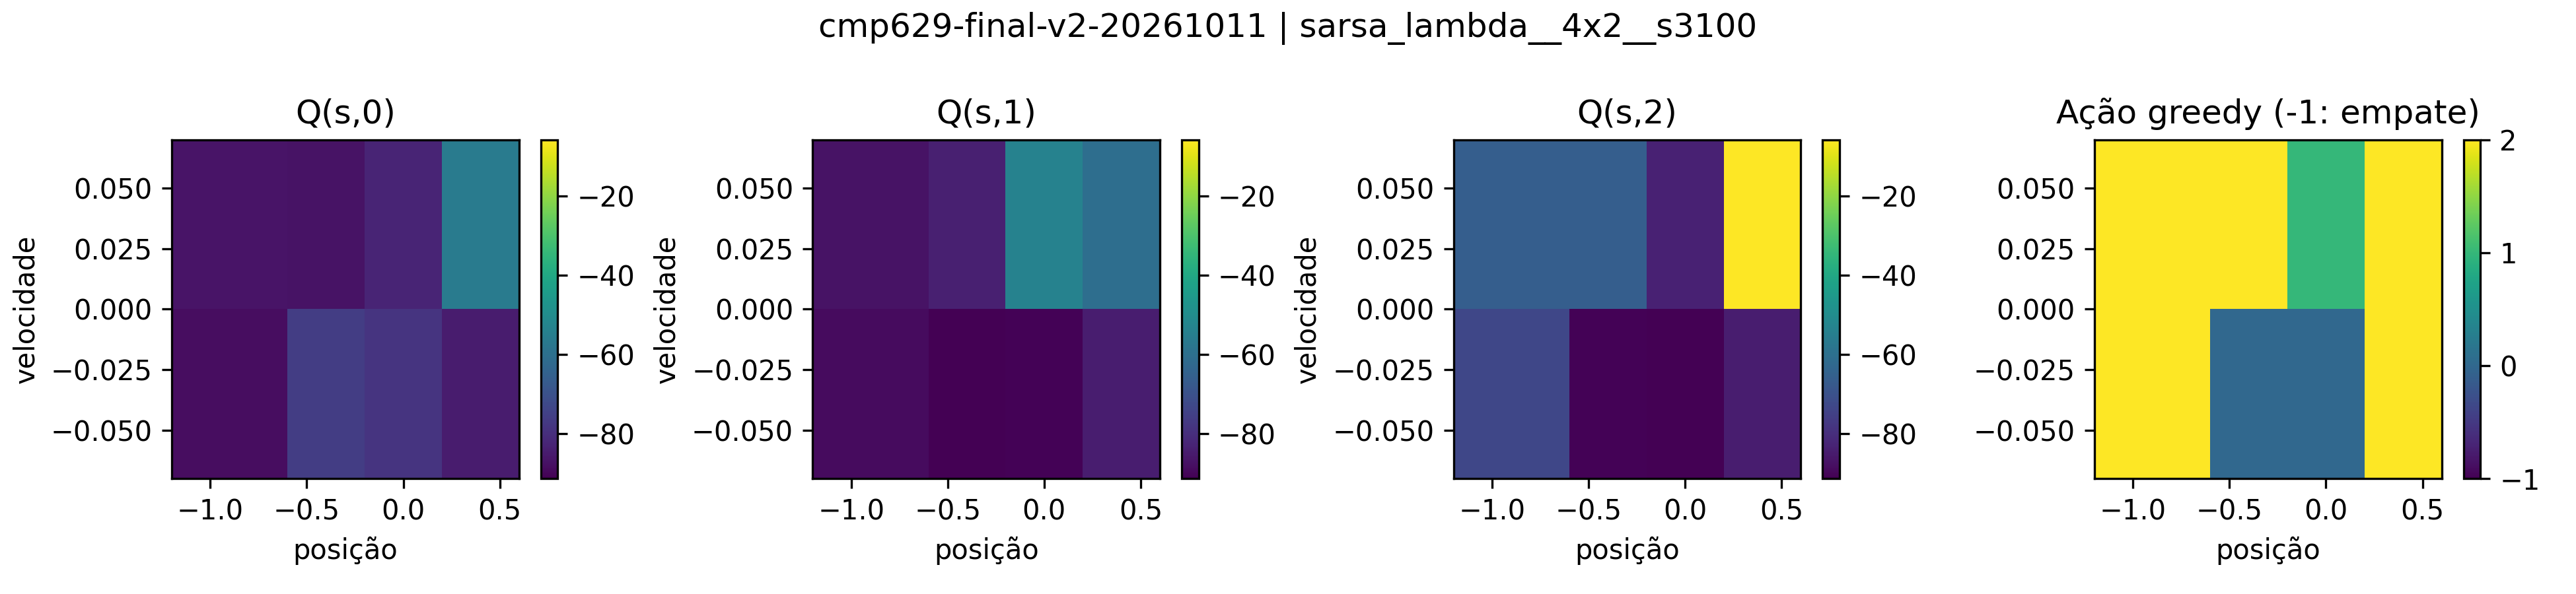

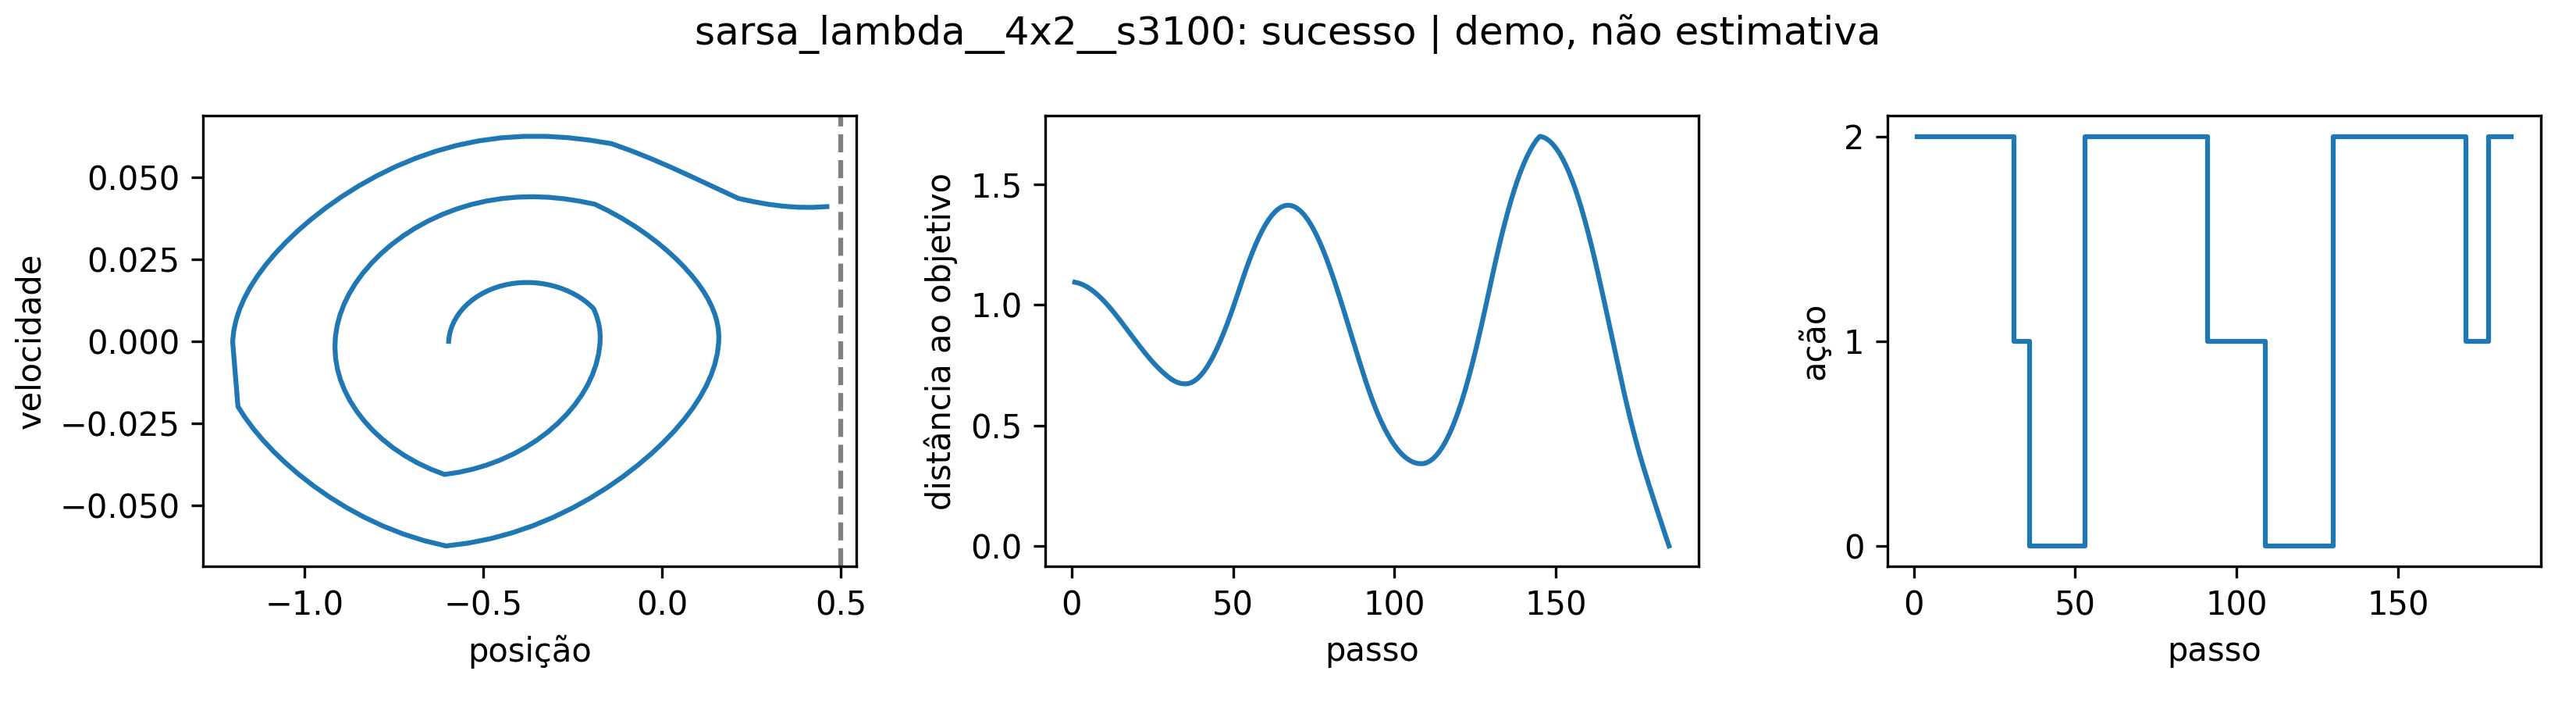

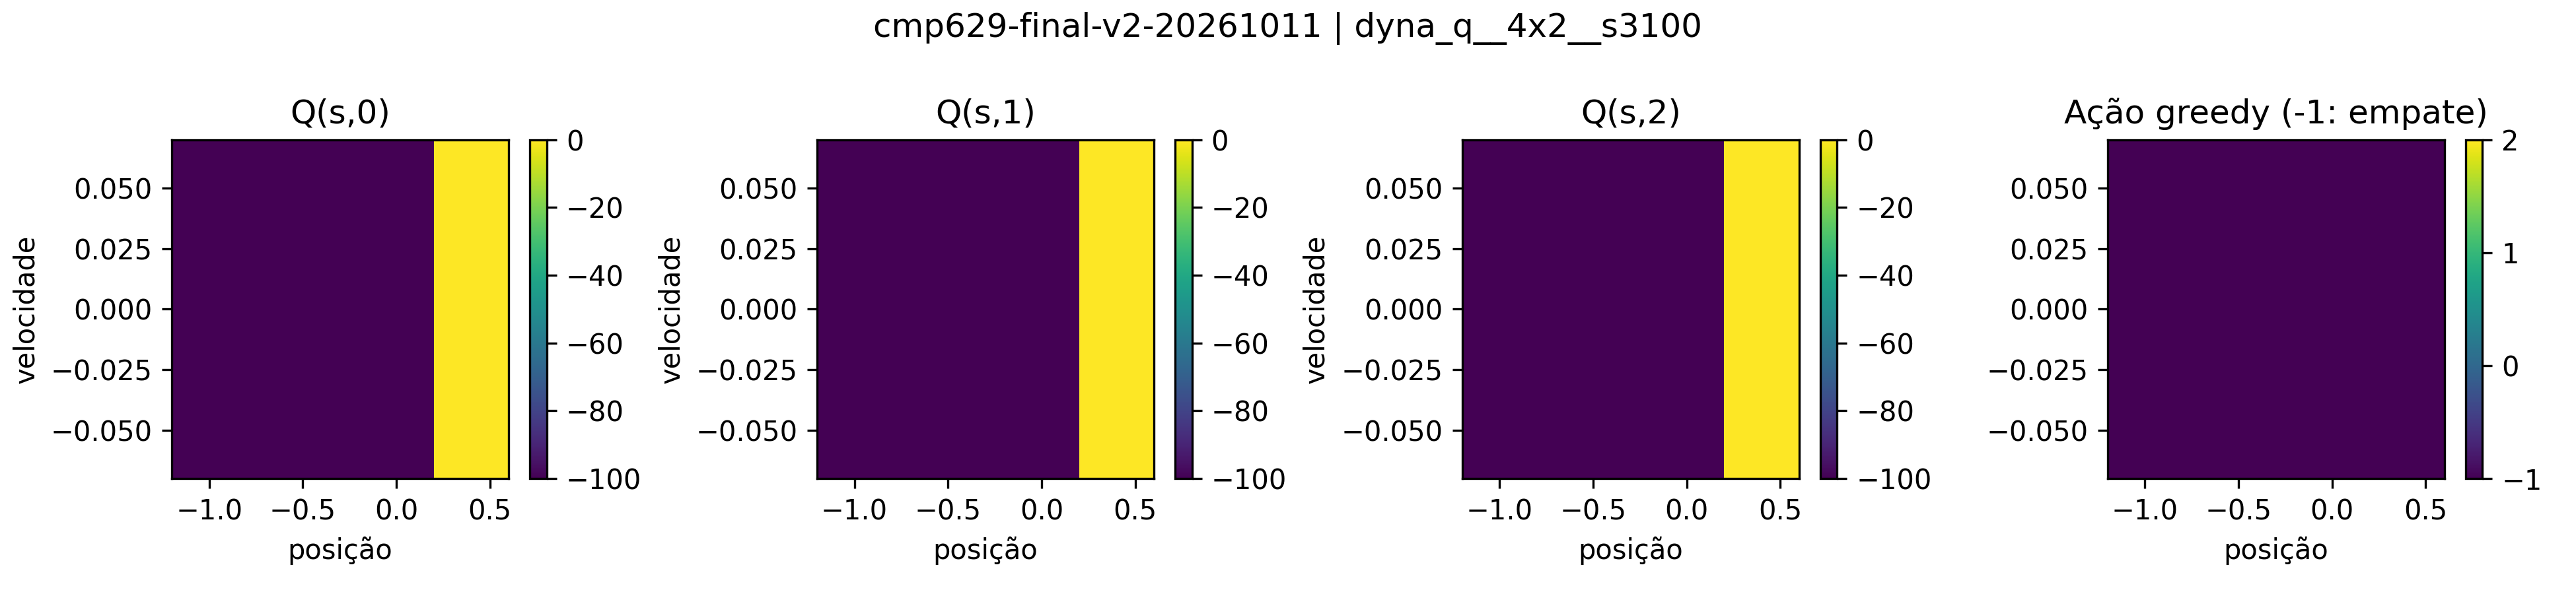

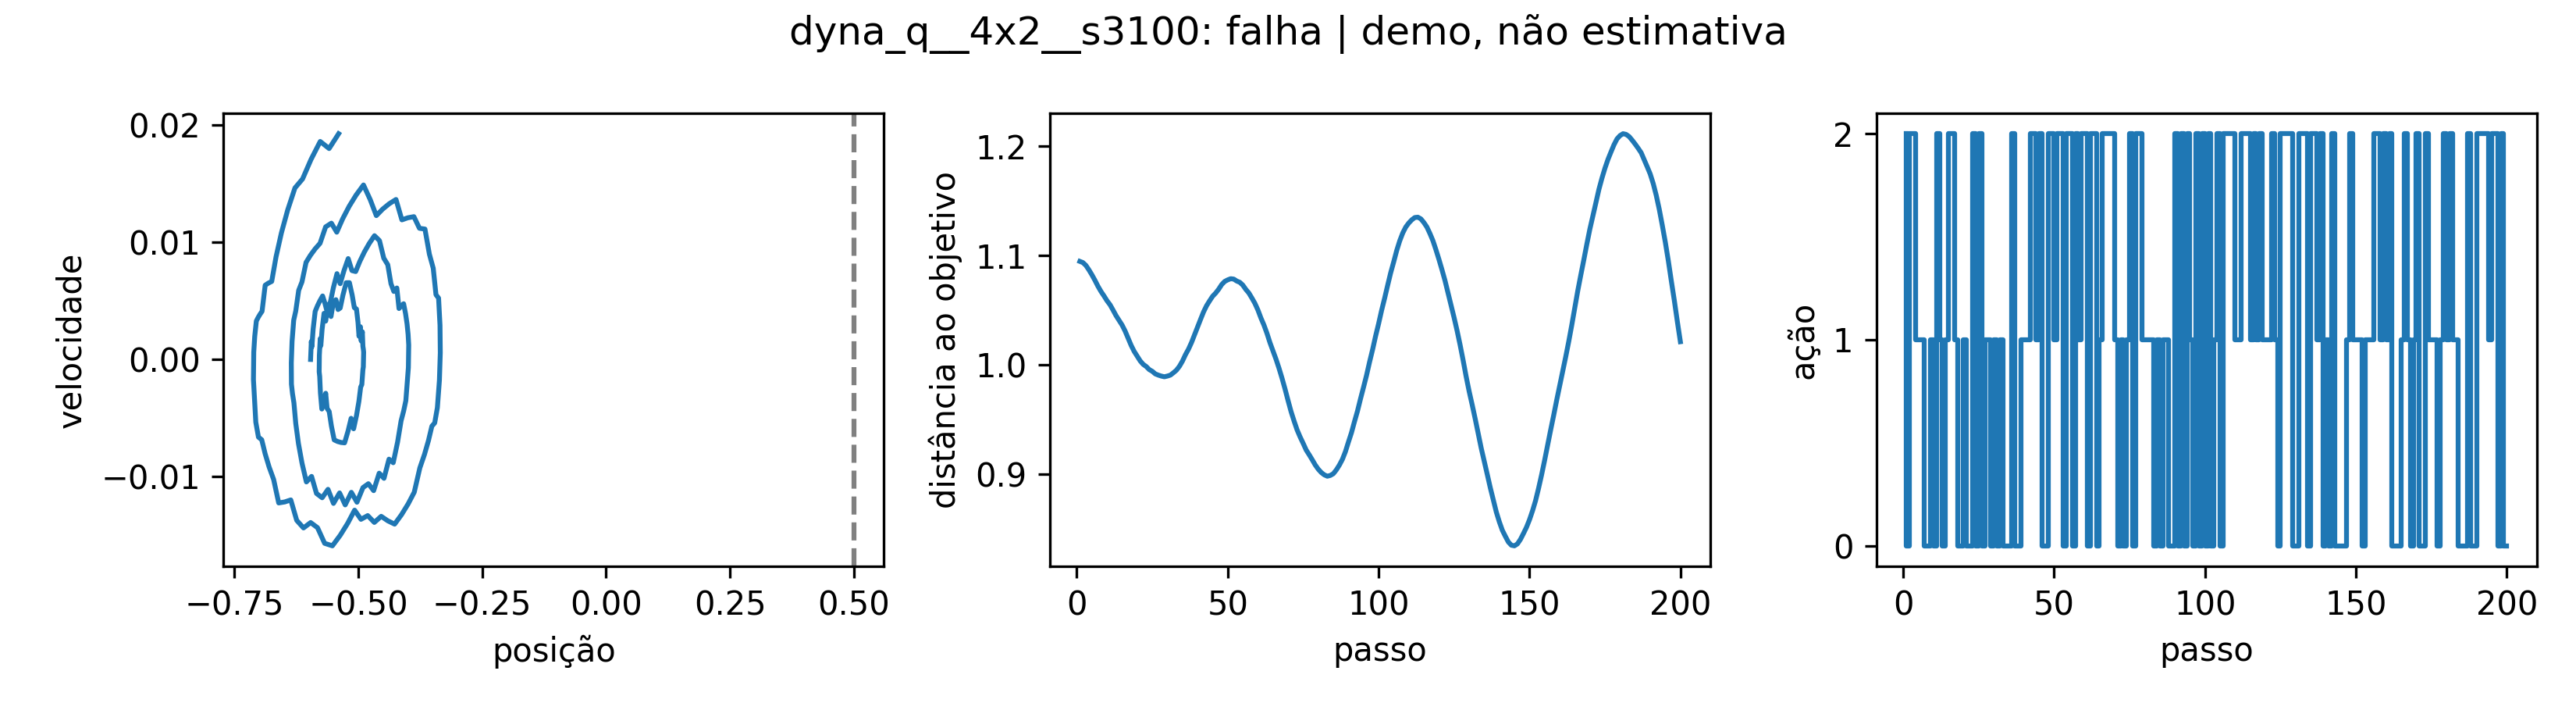

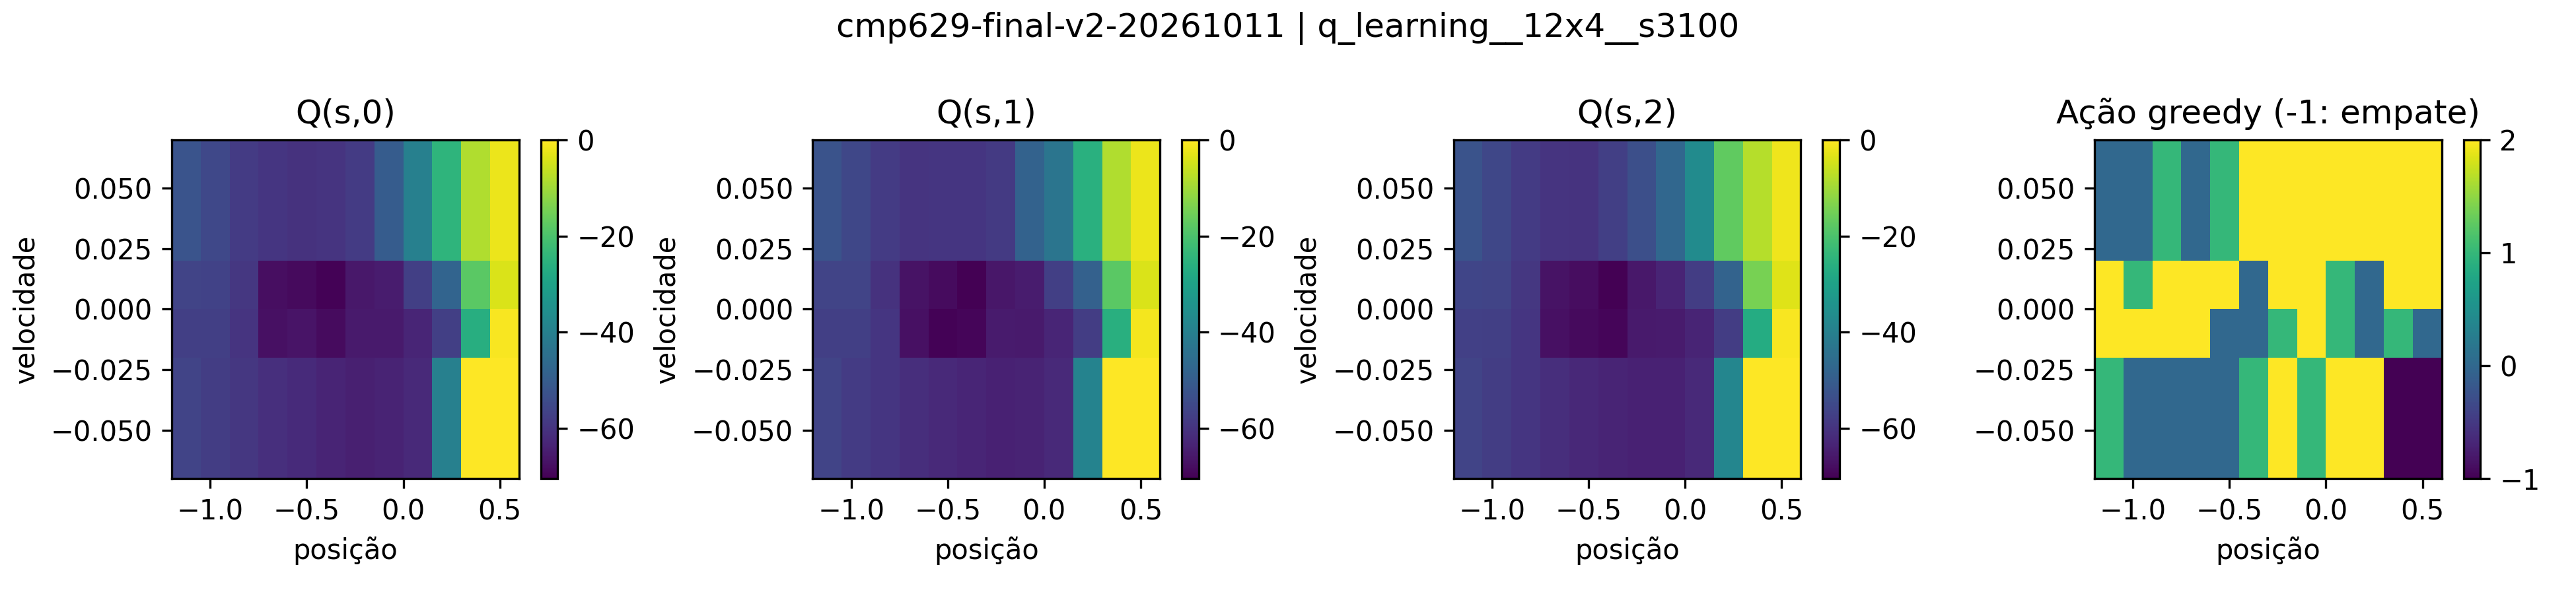

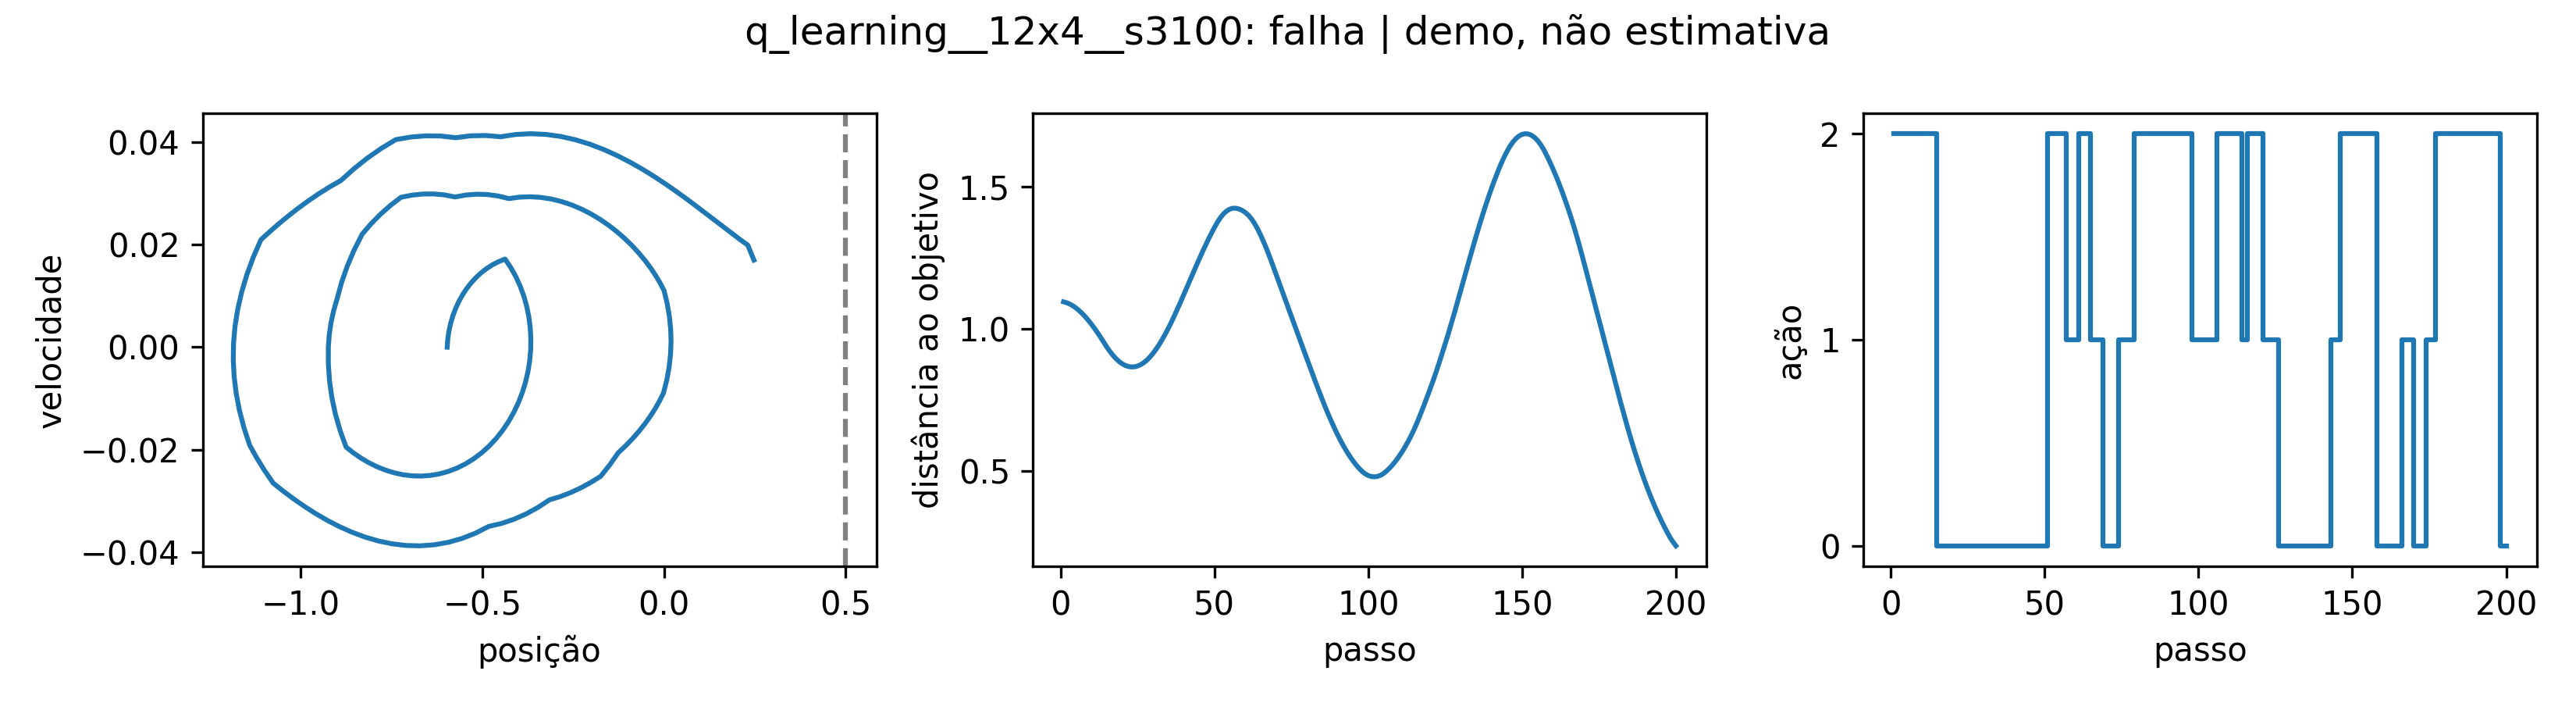

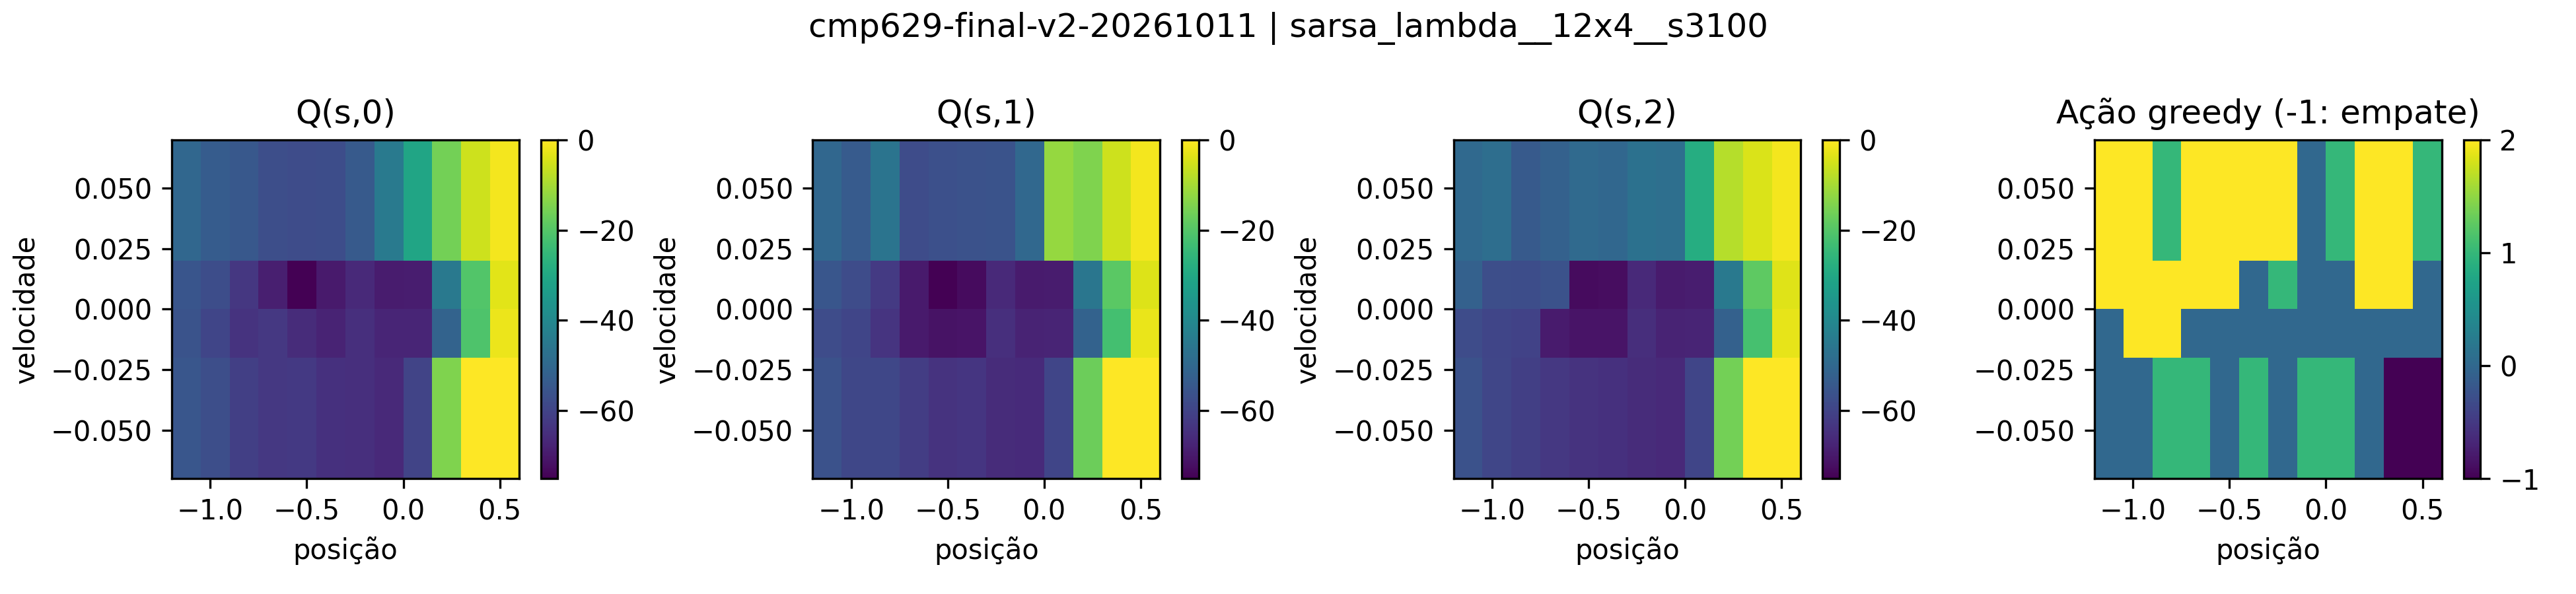

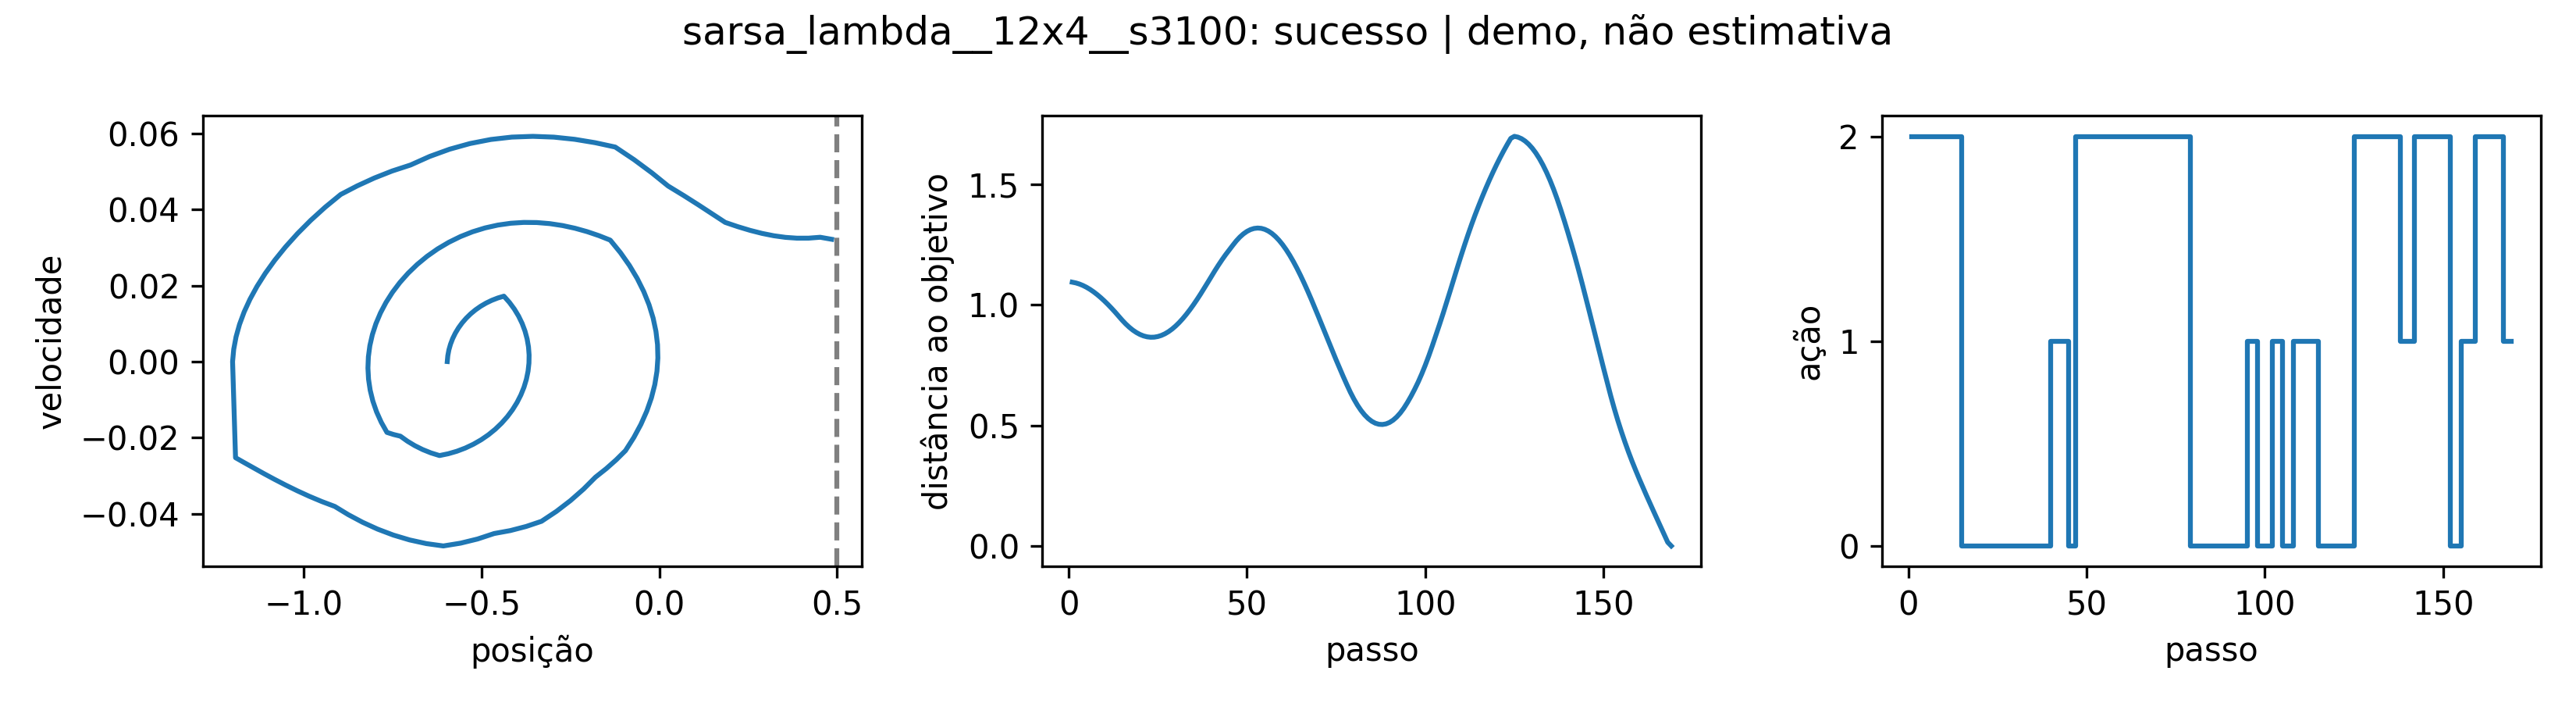

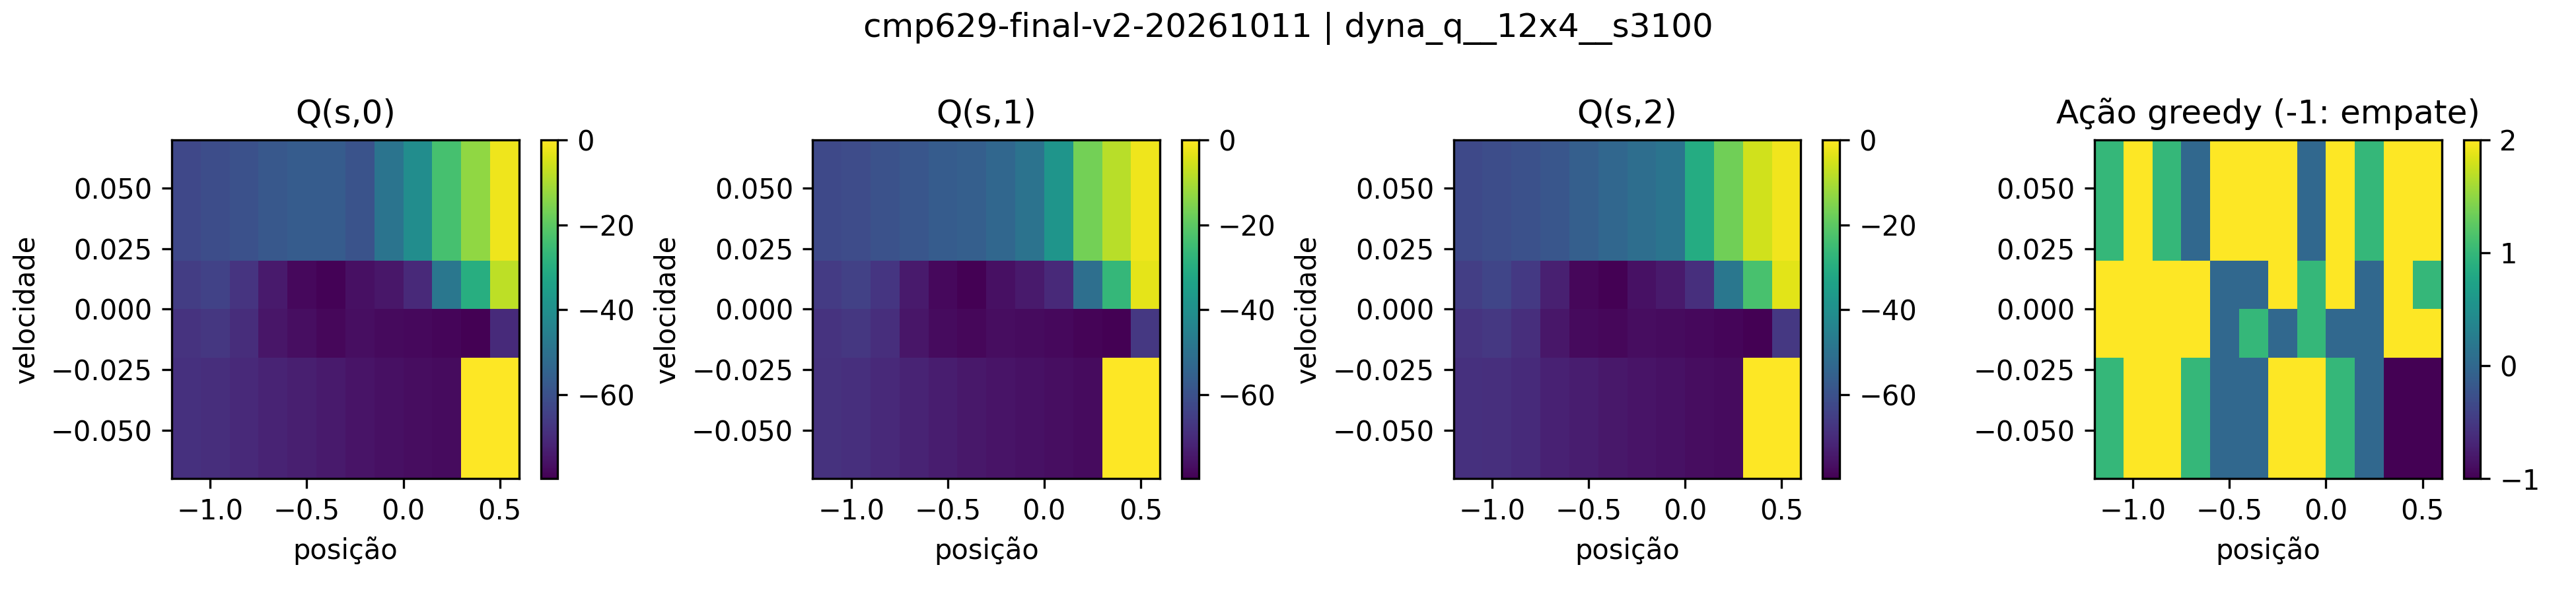

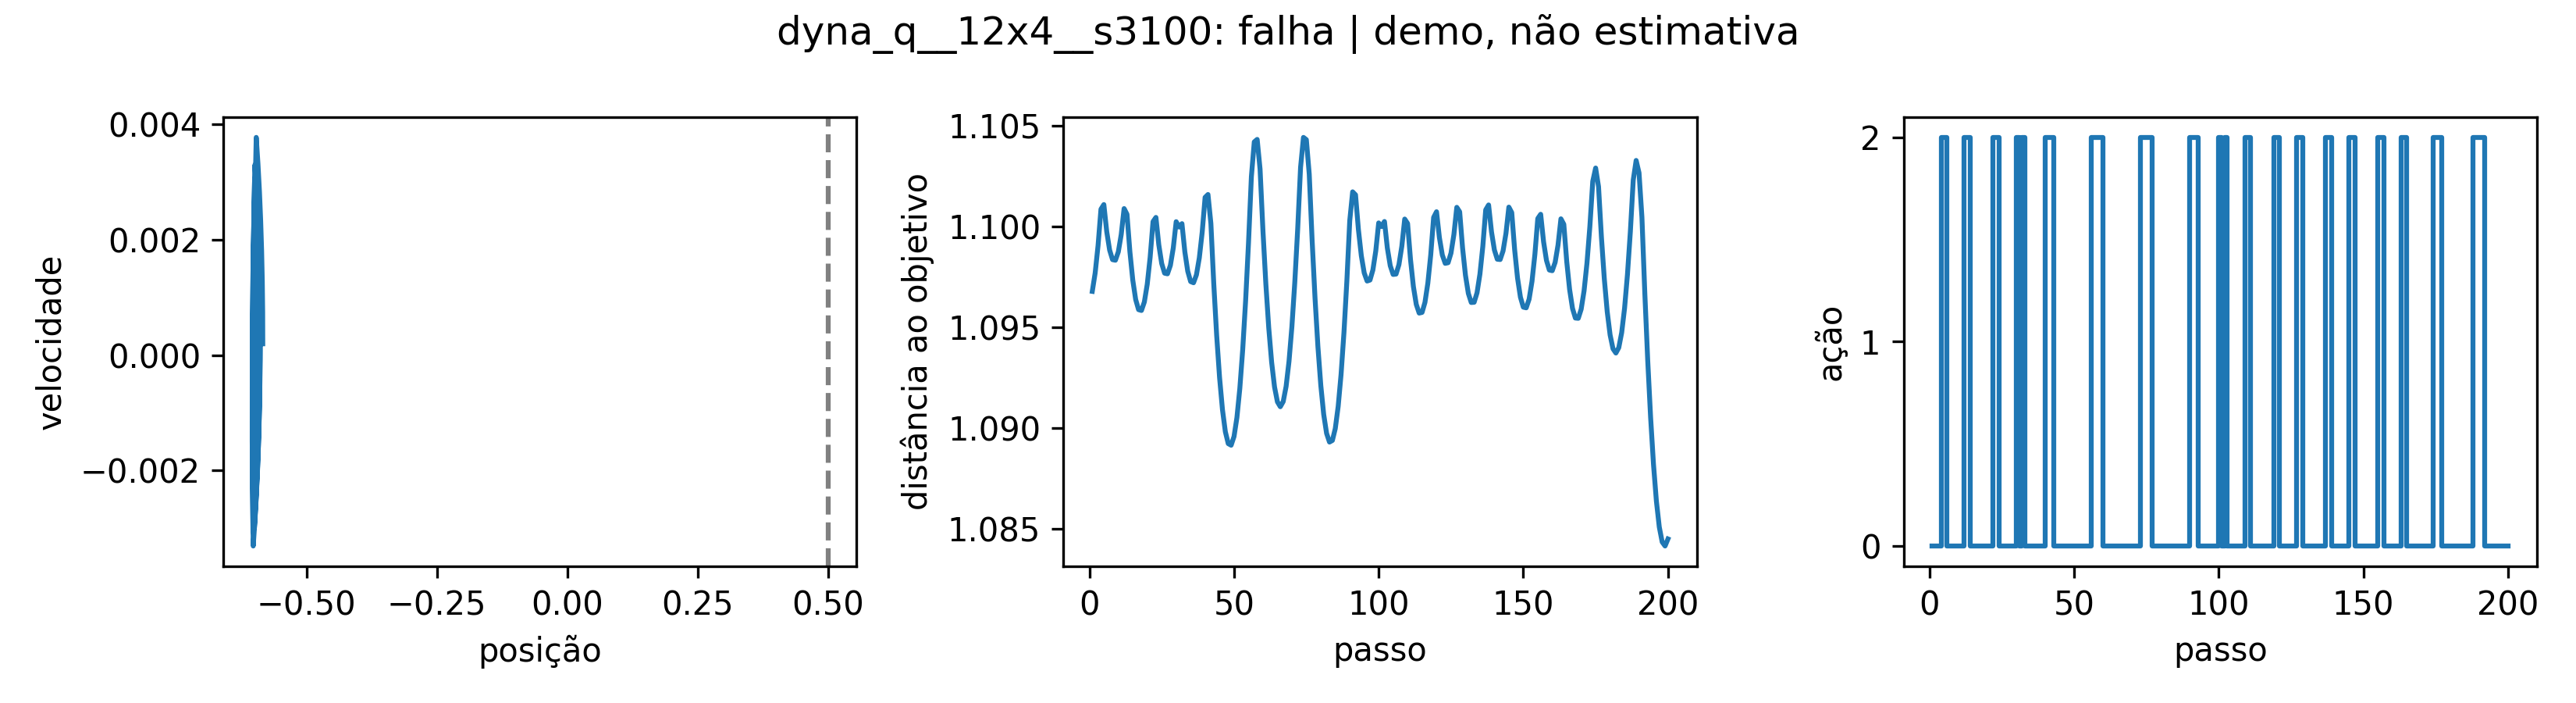

In [4]:
for disc in ("4x2","12x4"):
    for alg in ("q_learning","sarsa_lambda","dyna_q"):
        name=f"{alg}__{disc}__s3100"
        display(Image(verified(f"figuras/animacoes_final_v2/{name}.policy.png"),width=1050))
        display(Image(verified(f"figuras/animacoes_final_v2/{name}.trajectory.png"),width=1000))
    path=OUT/f"final_comparacao_{disc}.mp4"
    path.write_bytes(verified(f"figuras/animacoes_final_v2/comparacao_{disc}.mp4"))
    display(Video(str(path),embed=True,width=1050))

### Interpretação e limites

As diferenças valem para este protocolo, estas grades e os hiperparâmetros globais escolhidos. O efeito isolado de aliasing não foi identificado. Sensibilidade a N vem da triagem, não de novos ajustes finais. IC t com dez seeds é aproximado; conferir pontos individuais, mediana e DP. Comparações inferenciais AUC usam Friedman e Wilcoxon pareado com Holm por grade, conforme protocolo; sucesso avaliado é relatado descritivamente. Duração condicional omite políticas sem sucesso e traz seu denominador próprio. Latência e wall-clock dependem da máquina/carga.

Resultado/Discussão completos e condições de reprodução estão no relatório técnico público.

IC degenerado (DP zero, todas as políticas com 0% ou 100%) descreve esta amostra, não prova probabilidade populacional exatamente zero ou um. IC t não truncados estão na tabela; limites fora de [0,1] evidenciam a aproximação.

## Apêndice: proveniência da triagem

As 108 execuções históricas abaixo foram preservadas. Esta tabela é **exploratória** e não integra as 60 execuções finais. Todos os gráficos e vídeos exibidos acima são da campanha final; figuras de sensibilidade a N da triagem permanecem disponíveis no repositório, sem atribuição ao experimento final.

In [5]:
histories = json.loads(gzip.decompress(verified("dados/auditoria_v2/triagem_historicos.json.gz")))
assert len(histories) == 108
assert len({r["config_hash"] for r in histories}) == 108
assert all(len(r["training_metrics"]["episode_returns"]) == 1000 for r in histories)
seed_table = pd.read_csv(io.BytesIO(verified("dados/auditoria_v2/selected_seed_metrics.csv")))
assert len(seed_table) == 18 and seed_table.config_hash.nunique() == 18
summary = seed_table.groupby(["algorithm","discretization"]).agg(
    n_seeds=("seed","nunique"), sucesso_avaliacao=("evaluation_success_rate","mean"),
    dp_entre_seeds=("evaluation_success_rate","std"), sucesso_final_treino=("final_window_success","mean"),
    passos_com_falhas=("mean_steps_all","mean"))
display(summary.round(4))
summary.to_csv(OUT/"resumo_triagem.csv")

n_seeds  sucesso_avaliacao  dp_entre_seeds  \
algorithm    discretization                                               
dyna_q       12x4                  3             0.5133          0.4474   
             4x2                   3             0.0000          0.0000   
q_learning   12x4                  3             0.2267          0.2610   
             4x2                   3             0.6200          0.5415   
sarsa_lambda 12x4                  3             1.0000          0.0000   
             4x2                   3             0.6333          0.5493   

                             sucesso_final_treino  passos_com_falhas  
algorithm    discretization                                           
dyna_q       12x4                          0.4400           186.4867  
             4x2                           0.0000           200.0000  
q_learning   12x4                          0.3200           191.8000  
             4x2                           0.4000           166.0267  
sarsa_lambda 12x4                          0.9967           152.7867  
             4x2                           0.5433           164.1533

## Exportação e reprodução

Campanha final concluída e validada; nenhum retreino é necessário para apresentar. Scripts e bundles completos permitem reprodução. O Colab hospedado não foi executado por esta máquina; a validação usa kernel local limpo e downloads públicos.

In [6]:
academic = verified("relatorios/final_v2/RELATORIO_TECNICO.md")
(OUT/"RELATORIO_TECNICO.md").write_bytes(academic)
report = verified("relatorios/parecer_liberacao_final.md")
(OUT/"parecer_liberacao_final.md").write_bytes(report)
with zipfile.ZipFile("CMP629_apresentacao.zip","w",zipfile.ZIP_DEFLATED) as archive:
    for path in OUT.iterdir():
        if path.is_file(): archive.write(path,path.name)
print("Exportação: CMP629_apresentacao.zip; treinamento não executado por padrão")
# No Colab, descomente para baixar:
# from google.colab import files
# files.download("CMP629_apresentacao.zip")

Exportação: CMP629_apresentacao.zip; treinamento não executado por padrão
